# Mean width and degree-two harmonics of AR sliding-window point clouds

This notebook implements the proposed Monte Carlo estimator of mean width and
tests it on the AR(1), AR(2), and AR(3) realizations used in thesis Figures
2.1–2.3 (`AR1_experiment`, `AR2_experiment`, `AR3_experiment`). It compares
empirical mean width with population mean width and the existing empirical
minimum-width computation, then separates direction-integration error from
finite-sample support undercoverage.

**Run all cells from top to bottom.** The default experiments use dimensions
$k=1,\ldots,10$, 8,192 directions for the main curves, and six new time-series
realizations per fixed coefficient vector for the sample-size experiment.
All figures are displayed and saved as PDF and PNG, and all result tables and
simulation settings are exported beneath `outputs/mean_width/`. The notebook
only reads the existing AR utilities; it does not write thesis files.

The **degree-two extension** after the mean-width results compares population and empirical $Q_2$, its normalized spectrum, minimum-width approximations, Monte Carlo stability, and sample-size effects. Its exports are saved under `outputs/mean_width/q2/`.


## Estimator and normalization

Use **uniform probability measure** $\sigma$ on $\mathbb S^{k-1}$, so
$\sigma(\mathbb S^{k-1})=1$. With unnormalized surface-area measure, multiply
the result by $2\pi^{k/2}/\Gamma(k/2)$ (including surface mass 2 for $k=1$).
Here widths are full widths, not half-widths.

For $N_k=T-k+1$ backward windows $Y_t^{(k)}=(X_t,\ldots,X_{t-k+1})$,

$$\widehat w_{k,T}(u)
=\max_s\langle Y_s^{(k)},u\rangle-\min_t\langle Y_t^{(k)},u\rangle,
\qquad
\widehat{\overline w}_{k,T,M}
=\frac1M\sum_{m=1}^M\widehat w_{k,T}(U_{k,m}),$$

where $U_{k,m}=G_m/\|G_m\|_2$ and $G_m\overset{\mathrm{iid}}\sim N(0,I_k)$.
Each summand uses a fresh direction. This computes the maximum over all pairs
without forming an $N_k\times N_k$ distance or difference matrix. Projection
batches keep memory bounded. The computational cost is $O(MN_k k)$.

Conditional on the observed cloud, this is unbiased for its mean width.
The reported Monte Carlo standard error is
$s(\widehat w_{k,T}(U_{k,m}))/\sqrt M$; the bands $\pm1.96\,\mathrm{SE}$ are
approximate, pointwise integration intervals. They do **not** account for the
randomness or temporal dependence of the observed time series, and do not
cover the population mean width merely by increasing $M$.

For exact comparability with the figure-generation code, we use **all valid
windows at each $k$**. The thesis's common-endpoint convention $t=K,\ldots,T$
would instead use `sliding_window_point_cloud(x, K)[:, :k]`. This minor
finite-sample convention does not change the population target.


In [1]:
# If needed: %pip install numpy scipy pandas matplotlib threadpoolctl
import hashlib
import json
import platform
import sys
from pathlib import Path
from time import perf_counter

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import Markdown, display
from scipy.special import gammaln
from scipy.spatial import ConvexHull
from threadpoolctl import threadpool_limits

AR_CODE_DIR = next(
    (candidate.resolve()
     for root in (Path.cwd(), *Path.cwd().parents)
     for candidate in (root / 'Code' / 'Code_AR_processes', root)
     if (candidate / 'functions.py').is_file()
     and (candidate / 'plotting_functions.py').is_file()),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError('Run from the project root or the AR code folder.')
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Code.Code_AR_processes.functions import (
    ar_impulse_response,
    batched_geometric_width_curves,
    is_stationary,
    jones_ar_coefficients,
    simulate_uniform_ar,
    sliding_window_point_cloud,
    theoretical_ar_width_in_direction,
)

OUT = AR_CODE_DIR / 'outputs' / 'mean_width'
FIGURES = OUT / 'figures'
TABLES = OUT / 'tables'
for directory in (FIGURES, TABLES):
    directory.mkdir(parents=True, exist_ok=True)

K_VALUES = np.arange(1, 11)
T_MAIN = 2_000
BURNIN = 1_000
HALF_WIDTH = 1.0
M_MAIN = 8_192
DIRECTION_SEED = 20260909  # independent of every process-generation stream
HISTORY = 2_048
M_GRID = [32, 128, 512, 2_048, 8_192]
T_GRID = [500, 2_000, 8_000, 16_000]
M_SAMPLE = 1_024
N_SAMPLE_REPLICATIONS = 6
SAMPLE_SEED = 20260910
assert max(M_GRID) <= M_MAIN
assert min(T_GRID) >= max(K_VALUES)

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.2, 'pdf.fonttype': 42,
})
BLUE, ORANGE, GREEN, RED = '#1764ab', '#d66a16', '#24865b', '#b64052'

def show_and_save(fig, name):
    """Every figure produced here is exported before being displayed."""
    fig.savefig(FIGURES / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

STARTED = perf_counter()


## Reproduce the three thesis processes

The AR(2) recipe is in `ar_order_minimum_width.ipynb`. The AR(1) and AR(3)
recipes were recovered from the same notebook at repository revision
`93c46bc3de4709951f5ee07dd59d545d869e0538`, cells 31 and 37, before their
removal. These settings also reproduce the coefficients printed in the figures.

| Thesis figure | Process | Seed | Replication index (zero-based) |
|:--|:--|--:|--:|
| 2.1 / `AR1_experiment` | AR(1) | 20260813 | 0 |
| 2.2 / `AR2_experiment` | AR(2) | 20260814 | 1 |
| 2.3 / `AR3_experiment` | AR(3) | 20260816 | 9 |

For each row, create `default_rng(SeedSequence([seed, replication, 0]))`,
draw coefficients with `jones_ar_coefficients`, then use that **same generator**
for `simulate_uniform_ar`. All use $T=2,000$, burn-in 1,000, zero intercept,
and $\mathcal U[-1,1]$ innovations. Direction sampling uses separate streams,
so changing $M$ cannot change a simulated process.


In [2]:
PROCESS_SPECS = [
    {'p': 1, 'seed': 20260813, 'replication': 0, 'figure': '2.1',
     'expected_phi': [-0.5634983697098442],
     'expected_first3': [-0.45139989803512726, 0.052297660837431315, -0.7839590751217724]},
    {'p': 2, 'seed': 20260814, 'replication': 1, 'figure': '2.2',
     'expected_phi': [0.8699580024754807, -0.6377860428851445],
     'expected_first3': [-1.1956691233560368, -0.5126562095851637, -0.2490656618562122]},
    {'p': 3, 'seed': 20260816, 'replication': 9, 'figure': '2.3',
     'expected_phi': [0.6976038172777832, -0.8139939996478192, 0.6426157574018554],
     'expected_first3': [0.5454010194632091, -1.031345110136436, -0.4055141841529146]},
]
processes, provenance_rows = {}, []
for spec in PROCESS_SPECS:
    p = spec['p']
    rng = np.random.default_rng(np.random.SeedSequence([
        spec['seed'], spec['replication'], 0,
    ]))
    phi = jones_ar_coefficients(p, rng=rng)
    x = simulate_uniform_ar(phi, T_MAIN, BURNIN, HALF_WIDTH, rng=rng)
    stationary, eigenvalues = is_stationary(phi)
    assert stationary
    np.testing.assert_allclose(phi, spec['expected_phi'], rtol=0, atol=1e-14)
    np.testing.assert_allclose(x[:3], spec['expected_first3'], rtol=0, atol=1e-13)
    processes[p] = {'phi': phi, 'x': x, 'spec': spec}
    provenance_rows.append({
        'p': p, 'figure': spec['figure'], 'seed': spec['seed'],
        'replication': spec['replication'], 'T': len(x), 'burnin': BURNIN,
        'phi': json.dumps(phi.tolist()),
        'spectral_radius': float(np.max(np.abs(eigenvalues))),
        'series_sha256': hashlib.sha256(x.astype('<f8').tobytes()).hexdigest(),
    })
provenance = pd.DataFrame(provenance_rows)
provenance.to_csv(TABLES / 'process_provenance.csv', index=False)
display(provenance.drop(columns='series_sha256').round(6))


,p,figure,seed,replication,T,burnin,phi,spectral_radius
0,1,2.1,20260813,0,2000,1000,[-0.5634983697098442],0.563498
1,2,2.2,20260814,1,2000,1000,"[0.8699580024754807, -0.6377860428851445]",0.798615
2,3,2.3,20260816,9,2000,1000,"[0.6976038172777832, -0.8139939996478192, 0.64...",0.924528


## Monte Carlo implementation

The core estimator accepts any finite point cloud; no AR coefficients are
needed. At $k=1$, the sphere is $\{-1,+1\}$ and both directions have exactly
the same width, so integration has zero Monte Carlo error. Antipodal pairs
would also duplicate widths in higher dimensions and are not added as
independent samples.


In [3]:
def positive_int(value, name):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
        raise ValueError(f'{name} must be a positive integer.')
    return int(value)


def sphere_directions(k, m, rng=None):
    """Independent uniform probability draws on S^(k-1), including S^0."""
    k, m = positive_int(k, 'k'), positive_int(m, 'm')
    generator = np.random.default_rng(rng)
    if k == 1:
        return generator.choice([-1.0, 1.0], size=(m, 1))
    directions = generator.standard_normal((m, k))
    norms = np.linalg.norm(directions, axis=1)
    while np.any(norms == 0):
        zero = norms == 0
        directions[zero] = generator.standard_normal((zero.sum(), k))
        norms = np.linalg.norm(directions, axis=1)
    return directions / norms[:, None]


def validated_directions(directions, k):
    directions = np.asarray(directions, dtype=float)
    if (directions.ndim != 2 or directions.shape[1] != k
            or len(directions) < 1 or not np.isfinite(directions).all()):
        raise ValueError('Directions must be a nonempty finite M-by-k array.')
    if not np.allclose(np.linalg.norm(directions, axis=1), 1.0, rtol=1e-10, atol=1e-12):
        raise ValueError('Every supplied direction must have unit length.')
    return directions


def empirical_directional_widths(cloud, directions, direction_batch=256, point_batch=4096):
    """Projection ranges; never form pairwise point differences."""
    cloud = np.asarray(cloud, dtype=float)
    if (cloud.ndim != 2 or min(cloud.shape) < 1 or not np.isfinite(cloud).all()):
        raise ValueError('cloud must be a nonempty finite N-by-k array.')
    directions = validated_directions(directions, cloud.shape[1])
    direction_batch = positive_int(direction_batch, 'direction_batch')
    point_batch = positive_int(point_batch, 'point_batch')
    widths = np.empty(len(directions))
    # Single-threaded small matrix products avoid thread-launch overhead.
    with threadpool_limits(limits=1, user_api='blas'):
        for begin in range(0, len(directions), direction_batch):
            block = directions[begin:begin + direction_batch]
            low, high = np.full(len(block), np.inf), np.full(len(block), -np.inf)
            for row in range(0, len(cloud), point_batch):
                projections = cloud[row:row + point_batch] @ block.T
                low = np.minimum(low, projections.min(axis=0))
                high = np.maximum(high, projections.max(axis=0))
            widths[begin:begin + len(block)] = high - low
    return widths


def mc_summary(values):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or len(values) < 2 or not np.isfinite(values).all():
        raise ValueError('At least two finite directional values are needed for an SE.')
    estimate = float(values.mean())
    se = float(values.std(ddof=1) / np.sqrt(len(values)))
    return {'estimate': estimate, 'mc_se': se,
            'ci_low': estimate - 1.96 * se, 'ci_high': estimate + 1.96 * se,
            'M': len(values)}


def estimate_mean_width(cloud, m=4096, rng=None, *, directions=None):
    """Estimate full mean width; intervals describe direction integration only."""
    cloud = np.asarray(cloud, dtype=float)
    if cloud.ndim != 2 or min(cloud.shape) < 1:
        raise ValueError('cloud must be a nonempty N-by-k array.')
    if directions is None:
        directions = sphere_directions(cloud.shape[1], m, rng)
    values = empirical_directional_widths(cloud, directions)
    return {**mc_summary(values), 'directional_widths': values}


## Population benchmark from the AR support

For innovations supported on $[-a,a]$, the support is the infinite sum of
segments with generators $a\,g_j^{(k)}$, where
$g_j^{(k)}=(\psi_j,\psi_{j-1},\ldots,\psi_{j-k+1})$ and $\psi_\ell=0$ for
$\ell<0$. Therefore

$$w_k(u)=2a\sum_{j\ge0}|\langle g_j^{(k)},u\rangle|.$$

By rotational invariance,
$\mathbb E|\langle v,U\rangle|=c_k\|v\|_2$, where

$$c_k=\mathbb E|U_1|
=\frac{\Gamma(k/2)}{\sqrt\pi\,\Gamma((k+1)/2)},\qquad c_1=1.$$

Integrating each nonnegative summand gives the deterministic reference

$$\boxed{\overline w_k=2a\,c_k\sum_{j\ge0}\|g_j^{(k)}\|_2.}$$

This is a population benchmark using known simulation coefficients, not an
estimator available from an unknown process. We truncate at innovation lag
$H=2,048$ and compare with $2H$. Their agreement is a numerical convergence
diagnostic, **not a rigorous bound on the remaining infinite tail**. Every
generator through $H$ is retained; no small-generator threshold is applied.

The same-direction population average is also computed. Its difference from
the empirical average isolates support undercoverage, while its difference
from the deterministic reference measures population integration error.


In [4]:
def sphere_abs_coordinate_mean(k):
    k = positive_int(k, 'k')
    return float(np.exp(gammaln(k / 2) - 0.5 * np.log(np.pi) - gammaln((k + 1) / 2)))


def population_generators(phi, k, history=HISTORY, half_width=HALF_WIDTH):
    """Rows are a*g_j, j=0,...,history, with backward-window coordinates."""
    phi = np.asarray(phi, dtype=float)
    k, history = positive_int(k, 'k'), positive_int(history, 'history')
    if (phi.ndim != 1 or len(phi) < 1 or not np.isfinite(phi).all()
            or not is_stationary(phi)[0]):
        raise ValueError('Require a finite, stationary AR coefficient vector.')
    if history < k - 1 or not np.isfinite(half_width) or half_width <= 0:
        raise ValueError('Require history >= k-1 and half_width > 0.')
    psi = ar_impulse_response(phi, history)
    generators = np.zeros((history + 1, k))
    for coordinate in range(k):
        generators[coordinate:, coordinate] = half_width * psi[:history + 1 - coordinate]
    return generators


def population_mean_width(generators):
    k = generators.shape[1]
    return float(2 * sphere_abs_coordinate_mean(k) * np.linalg.norm(generators, axis=1).sum())


def population_directional_widths(generators, directions, batch=256):
    directions = validated_directions(directions, generators.shape[1])
    batch = positive_int(batch, 'batch')
    widths = np.empty(len(directions))
    with threadpool_limits(limits=1, user_api='blas'):
        for begin in range(0, len(directions), batch):
            block = directions[begin:begin + batch]
            widths[begin:begin + len(block)] = 2 * np.abs(generators @ block.T).sum(axis=0)
    return widths


## Numerical checks independent of the AR experiment

Check projection ranges against an explicit maximum over point pairs;
translation, reflection, scaling, and simultaneous rotation of points and
directions; the exact interval result in one dimension; and known mean widths
of a segment and a cube. For a two-dimensional cloud, the exact empirical
mean width is the convex-hull perimeter divided by $\pi$, providing an
independent check of directional integration. We also compare the population
formula against the closed-form geometric tail for an AR(1) process.


In [5]:
check_rng = np.random.default_rng(7342)
toy = check_rng.normal(size=(13, 3))
u = sphere_directions(3, 37, check_rng)
widths = empirical_directional_widths(toy, u, direction_batch=7, point_batch=4)
pairwise = np.einsum('ijk,mk->ijm', toy[:, None, :] - toy[None, :, :], u).max(axis=(0, 1))
np.testing.assert_allclose(widths, pairwise, atol=1e-12)
np.testing.assert_allclose(widths, empirical_directional_widths(toy + [4, -2, 7], u), atol=1e-12)
np.testing.assert_allclose(widths, empirical_directional_widths(toy, -u), atol=1e-12)
np.testing.assert_allclose(3 * widths, empirical_directional_widths(-3 * toy, u), atol=1e-12)
rotation, _ = np.linalg.qr(check_rng.normal(size=(3, 3)))
np.testing.assert_allclose(widths, empirical_directional_widths(toy @ rotation, u @ rotation), atol=1e-12)
interval = estimate_mean_width(np.array([[-2.0], [1.0], [5.0]]), m=100, rng=4)
assert interval['estimate'] == 7 and interval['mc_se'] == 0
assert estimate_mean_width(np.zeros((1, 3)), m=10, rng=4)['estimate'] == 0
np.testing.assert_allclose(sphere_directions(4, 30, 51), sphere_directions(4, 30, 51))

theta = np.linspace(0, 2 * np.pi, 32_768, endpoint=False)
circle = np.column_stack([np.cos(theta), np.sin(theta)])
segment = np.array([[-2.0, 0.0], [2.0, 0.0]])
segment_error = abs(empirical_directional_widths(segment, circle).mean() - 8 / np.pi)
assert segment_error < 1e-7
polygon = check_rng.normal(size=(30, 2))
polygon_error = abs(empirical_directional_widths(polygon, circle).mean() - ConvexHull(polygon).area / np.pi)
assert polygon_error < 1e-7  # scipy's 2D .area is the perimeter
cube_error = max(abs(population_mean_width(population_generators([0.0], k, 32))
                     - 2 * k * sphere_abs_coordinate_mean(k)) for k in range(1, 11))
assert cube_error < 1e-12

ar1_errors = []
b = abs(processes[1]['phi'][0])
for k in K_VALUES:
    partial_norms = np.sqrt(np.cumsum(b ** (2 * np.arange(k))))
    exact_ar1 = 2 * sphere_abs_coordinate_mean(k) * (partial_norms[:-1].sum() + partial_norms[-1] / (1 - b))
    ar1_errors.append(abs(population_mean_width(population_generators(processes[1]['phi'], k)) - exact_ar1))
assert max(ar1_errors) < 1e-11
test_generators = population_generators(processes[3]['phi'], 4)
test_u = sphere_directions(4, 7, 184)
np.testing.assert_allclose(
    population_directional_widths(test_generators, test_u),
    [theoretical_ar_width_in_direction(processes[3]['phi'], direction, history=HISTORY) for direction in test_u],
    rtol=1e-12, atol=1e-12,
)
checks = {'pairwise_range_max_error': float(np.max(abs(widths - pairwise))),
          'segment_angular_error': segment_error, 'polygon_perimeter_error': polygon_error,
          'cube_formula_error': cube_error, 'ar1_closed_form_max_error': max(ar1_errors)}
display(pd.Series(checks, name='absolute error'))
print('All mathematical and reproducibility checks passed.')


All mathematical and reproducibility checks passed.


pairwise_range_max_error     1.332268e-15
segment_angular_error        7.802230e-09
polygon_perimeter_error      9.374239e-10
cube_formula_error           0.000000e+00
ar1_closed_form_max_error    8.881784e-16
Name: absolute error, dtype: float64

## Experiment 1: the three thesis realizations across dimension

For each process and dimension, use 8,192 iid directions. Empirical and
population directional widths share those directions. Random streams are
independent across dimensions. Recompute the empirical minimum-width curve
with the figure settings (3 starts, 500 iterations, initial step 0.2,
geometric decay 0.99); these numerical minima remain optimization estimates.
The vertical marker is the known $p+1$, not a selected order.


In [6]:
main_rows, truncation_rows, directional_cache = [], [], {}
for p, process in processes.items():
    phi, x, spec = process['phi'], process['x'], process['spec']
    with threadpool_limits(limits=1, user_api='blas'):
        _, minimum_widths, _ = batched_geometric_width_curves(
            x, K_VALUES, seed=spec['seed'], replication=spec['replication'],
            starts=3, iterations=500, initial_step=0.2, geometric_decay=0.99,
        )
    for k, min_width in zip(K_VALUES, minimum_widths):
        cloud = sliding_window_point_cloud(x, int(k))
        directions = sphere_directions(int(k), M_MAIN, np.random.SeedSequence([DIRECTION_SEED, p, int(k), 0]))
        empirical = estimate_mean_width(cloud, directions=directions)
        generators = population_generators(phi, k)
        pop_values = population_directional_widths(generators, directions)
        population = population_mean_width(generators)
        population_2h = population_mean_width(population_generators(phi, k, 2 * HISTORY))
        tail_change = abs(population_2h - population)
        assert tail_change <= 1e-10 * max(1.0, population), 'Increase HISTORY for this process.'
        gap_values = pop_values - empirical['directional_widths']
        assert gap_values.min() >= -1e-9  # observed support inclusion, to numerical tolerance
        gap = mc_summary(gap_values)
        directional_cache[p, int(k)] = {'directions': directions,
                                      'empirical': empirical['directional_widths'],
                                      'population': pop_values}
        main_rows.append({
            'p': p, 'k': int(k), 'T': len(x), 'N_windows': len(cloud), 'M': M_MAIN,
            'empirical_mean': empirical['estimate'], 'empirical_mc_se': empirical['mc_se'],
            'population_mean_H': population, 'population_mc_mean': pop_values.mean(),
            'population_mc_se': mc_summary(pop_values)['mc_se'],
            'paired_support_gap': gap['estimate'], 'paired_gap_mc_se': gap['mc_se'],
            'paired_gap_percent': 100 * gap['estimate'] / population,
            'empirical_minimum': min_width,
            'population_minimum_plateau': 2 * HALF_WIDTH / np.linalg.norm(np.r_[1.0, -phi]) if k >= p + 1 else np.nan,
            'empirical_mean_over_sqrt_k': empirical['estimate'] / np.sqrt(k),
            'population_mean_over_sqrt_k': population / np.sqrt(k),
        })
        truncation_rows.append({'p': p, 'k': int(k), 'H': HISTORY,
                                'mean_H': population, 'mean_2H': population_2h,
                                'absolute_change': tail_change})
    print(f'Completed main AR({p}) curves.')
main_results = pd.DataFrame(main_rows)
truncation_results = pd.DataFrame(truncation_rows)
main_results.to_csv(TABLES / 'dimension_curves.csv', index=False)
truncation_results.to_csv(TABLES / 'population_history_check.csv', index=False)
display(main_results[main_results['k'].isin([1, 2, 3, 4, 10])][
    ['p', 'k', 'empirical_mean', 'empirical_mc_se', 'population_mean_H', 'paired_gap_percent', 'empirical_minimum']
].round(5))
print('Largest H-to-2H change:', truncation_results['absolute_change'].max())


Completed main AR(1) curves.
Completed main AR(2) curves.
Completed main AR(3) curves.
Largest H-to-2H change: 0.0


,p,k,empirical_mean,empirical_mc_se,population_mean_H,paired_gap_percent,empirical_minimum
0,1,1,3.74185,0.00000,4.58188,18.33377,3.74185
1,1,2,3.68684,0.01183,4.62139,20.02847,1.73555
2,1,3,3.77114,0.01189,4.87623,22.59578,1.73487
3,1,4,3.85257,0.01131,5.17597,25.11388,1.73455
9,1,10,4.21810,0.00838,6.91519,38.95940,1.72174
10,2,1,5.66627,0.00000,8.13428,30.34080,5.66627
11,2,2,5.61168,0.01456,8.19790,31.57468,3.61146
12,2,3,5.62093,0.01650,8.39050,33.01911,1.35613
13,2,4,5.61476,0.01765,8.57138,34.66730,1.35307
19,2,10,5.88535,0.01746,10.12705,41.50566,1.31130


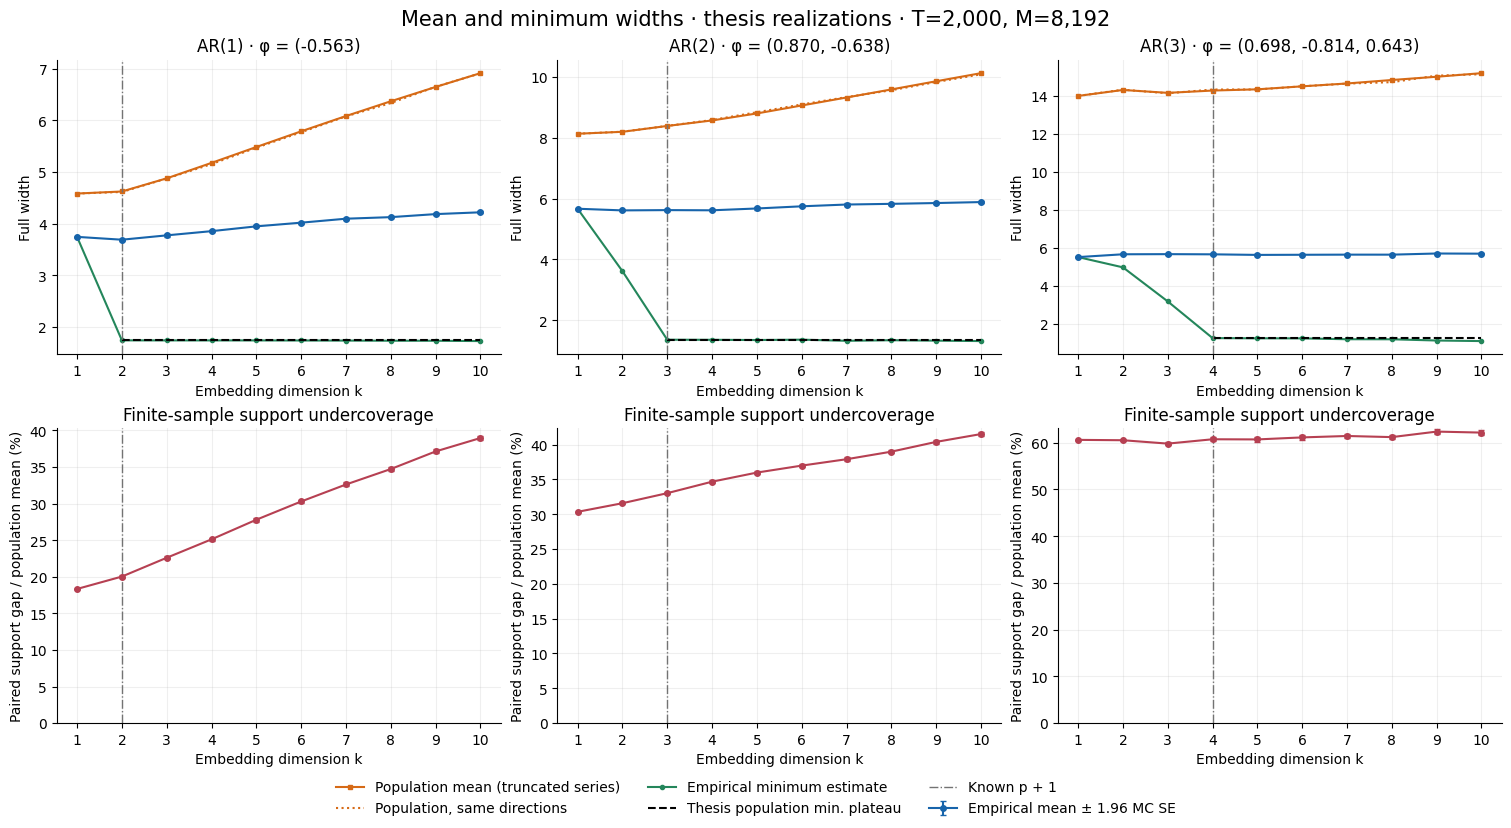

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2), layout='constrained')
for column, p in enumerate(processes):
    data = main_results[main_results.p == p]
    ax = axes[0, column]
    ax.errorbar(data.k, data.empirical_mean, yerr=1.96 * data.empirical_mc_se,
                color=BLUE, marker='o', ms=4, capsize=2, label='Empirical mean ± 1.96 MC SE')
    ax.plot(data.k, data.population_mean_H, color=ORANGE, marker='s', ms=3, label='Population mean (truncated series)')
    ax.plot(data.k, data.population_mc_mean, color=ORANGE, linestyle=':', label='Population, same directions')
    ax.plot(data.k, data.empirical_minimum, color=GREEN, marker='.', label='Empirical minimum estimate')
    ax.plot(data.k, data.population_minimum_plateau, color='black', linestyle='--', label='Thesis population min. plateau')
    phi_text = ', '.join(f'{v:.3f}' for v in processes[p]['phi'])
    ax.set(title=f'AR({p}) · φ = ({phi_text})', xlabel='Embedding dimension k', ylabel='Full width', xticks=K_VALUES)
    axes[1, column].errorbar(data.k, data.paired_gap_percent,
                            yerr=196 * data.paired_gap_mc_se / data.population_mean_H,
                            color=RED, marker='o', ms=4, capsize=2)
    axes[1, column].set(xlabel='Embedding dimension k', ylabel='Paired support gap / population mean (%)',
                       xticks=K_VALUES, ylim=(0, None), title='Finite-sample support undercoverage')
    for a in axes[:, column]:
        a.axvline(p + 1, color='0.45', linestyle='-.', linewidth=1, label='Known p + 1')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, frameon=False)
fig.suptitle(f'Mean and minimum widths · thesis realizations · T={T_MAIN:,}, M={M_MAIN:,}', fontsize=15)
show_and_save(fig, '01_mean_width_vs_dimension')


### Dimension scaling and the order-selection question

Even white noise has a growing mean width: its support is $[-a,a]^k$, hence
$\overline w_k=2ak c_k$, asymptotically proportional to $\sqrt{k}$. Thus the
minimum-width plateau rule cannot be transferred directly to raw mean width.
The following diagnostic plots $\overline w_k/\sqrt{k}$ and finite differences
of the raw curves. A change near $p+1$ is exploratory evidence, not a proved
order selector. Dividing by $\sqrt{k}$ also changes the functional being examined.

Empirical increments also contain Monte Carlo noise from independent direction banks across dimensions; small fluctuations should not be interpreted as an order signal.


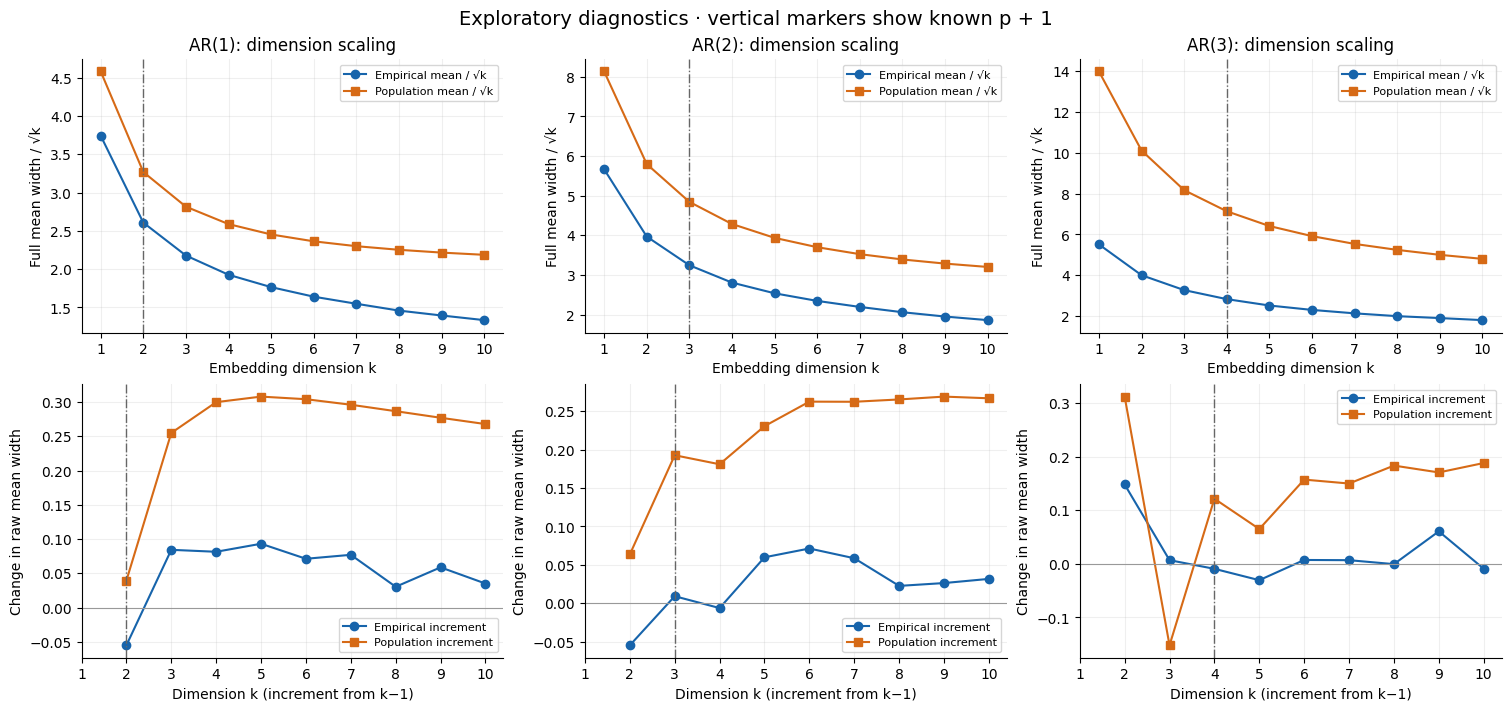

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.0), layout='constrained')
for column, p in enumerate(processes):
    data = main_results[main_results.p == p]
    axes[0, column].plot(data.k, data.empirical_mean_over_sqrt_k, 'o-', color=BLUE, label='Empirical mean / √k')
    axes[0, column].plot(data.k, data.population_mean_over_sqrt_k, 's-', color=ORANGE, label='Population mean / √k')
    axes[0, column].set(title=f'AR({p}): dimension scaling', xlabel='Embedding dimension k', ylabel='Full mean width / √k')
    axes[1, column].plot(data.k.to_numpy()[1:], np.diff(data.empirical_mean), 'o-', color=BLUE, label='Empirical increment')
    axes[1, column].plot(data.k.to_numpy()[1:], np.diff(data.population_mean_H), 's-', color=ORANGE, label='Population increment')
    axes[1, column].axhline(0, color='0.6', linewidth=0.8)
    axes[1, column].set(xlabel='Dimension k (increment from k−1)', ylabel='Change in raw mean width')
    for a in axes[:, column]:
        a.axvline(p + 1, color='0.4', linestyle='-.', linewidth=1)
        a.set_xticks(K_VALUES)
        a.legend(fontsize=8)
fig.suptitle('Exploratory diagnostics · vertical markers show known p + 1', fontsize=14)
show_and_save(fig, '02_dimension_scaling_and_increments')


## Experiment 2: increase the number of directions, holding the data fixed

Use nested prefixes of each main direction bank, at $k=p+1$ and $k=10$.
These estimates are correlated across $M$. The population spherical integral
is known up to history truncation, so its Monte Carlo error can be measured
directly. For the empirical integral, the dashed line uses the full 8,192
directions as a reference, not ground truth. The population–empirical gap
does not disappear just by drawing more directions.


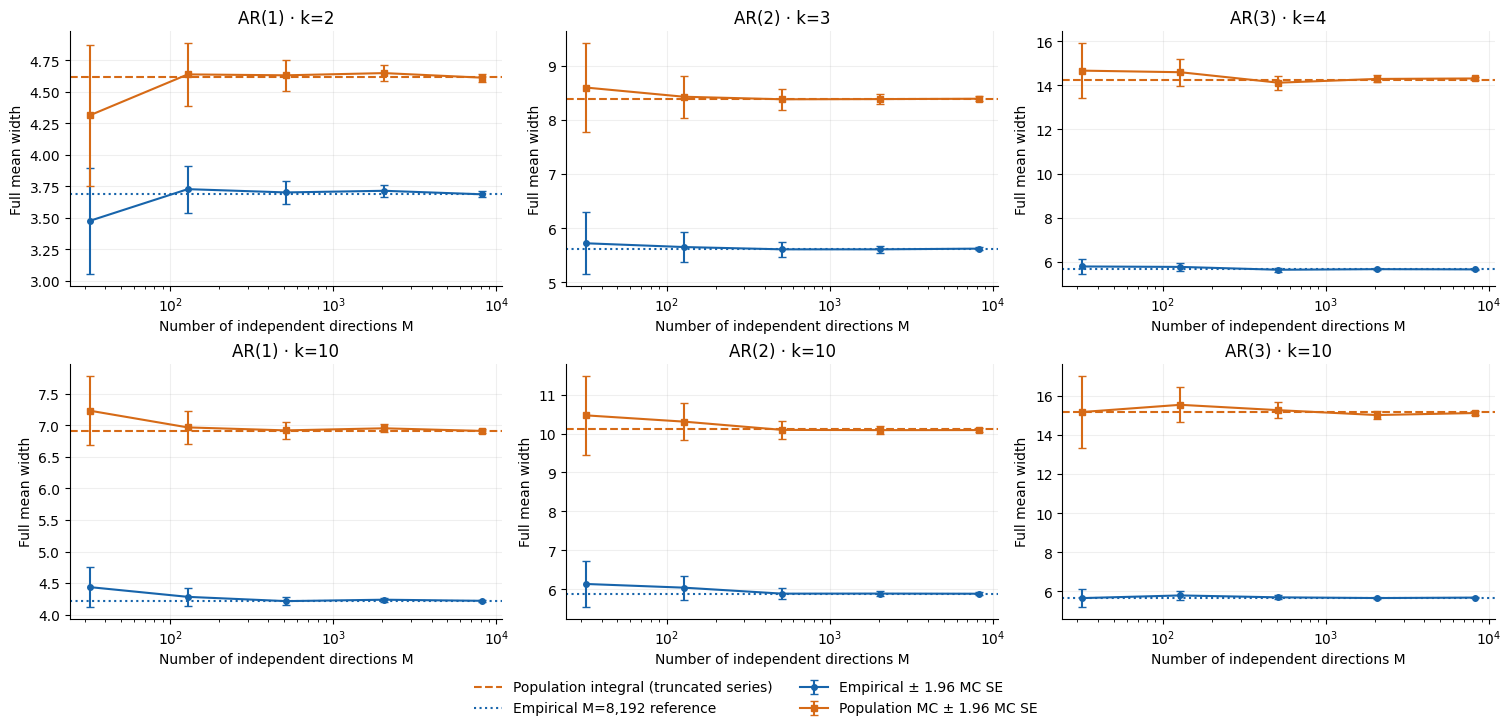

,p,k,M,empirical_mc_se,population_mc_se,population_mc_error
4,1,2,8192,0.011828,0.015674,-0.008950
9,1,10,8192,0.008381,0.016413,-0.002974
14,2,3,8192,0.016497,0.023087,0.000895
19,2,10,8192,0.017464,0.028075,-0.038398
24,3,4,8192,0.012370,0.041499,0.053134
29,3,10,8192,0.013933,0.051970,-0.054585


In [9]:
mc_rows = []
for p in processes:
    for k in (p + 1, 10):
        cached = directional_cache[p, k]
        reference = float(main_results.loc[(main_results.p == p) & (main_results.k == k), 'population_mean_H'].iloc[0])
        for m in M_GRID:
            emp = mc_summary(cached['empirical'][:m])
            pop = mc_summary(cached['population'][:m])
            mc_rows.append({'p': p, 'k': k, 'M': m, 'empirical_mean': emp['estimate'],
                            'empirical_mc_se': emp['mc_se'], 'population_mc_mean': pop['estimate'],
                            'population_mc_se': pop['mc_se'], 'population_mean_H': reference,
                            'population_mc_error': pop['estimate'] - reference,
                            'empirical_full_M_reference': cached['empirical'].mean()})
mc_results = pd.DataFrame(mc_rows)
mc_results.to_csv(TABLES / 'direction_count_sweep.csv', index=False)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.2), layout='constrained')
for column, p in enumerate(processes):
    for row, k in enumerate((p + 1, 10)):
        data = mc_results[(mc_results.p == p) & (mc_results.k == k)]
        ax = axes[row, column]
        ax.errorbar(data.M, data.empirical_mean, yerr=1.96 * data.empirical_mc_se,
                    color=BLUE, marker='o', ms=4, capsize=3, label='Empirical ± 1.96 MC SE')
        ax.errorbar(data.M, data.population_mc_mean, yerr=1.96 * data.population_mc_se,
                    color=ORANGE, marker='s', ms=4, capsize=3, label='Population MC ± 1.96 MC SE')
        ax.axhline(data.population_mean_H.iloc[0], color=ORANGE, linestyle='--', label='Population integral (truncated series)')
        ax.axhline(data.empirical_full_M_reference.iloc[0], color=BLUE, linestyle=':', label=f'Empirical M={M_MAIN:,} reference')
        ax.set(xscale='log', xlabel='Number of independent directions M', ylabel='Full mean width', title=f'AR({p}) · k={k}')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=2, frameon=False)
show_and_save(fig, '03_monte_carlo_direction_convergence')
display(mc_results[mc_results.M == max(M_GRID)][
    ['p', 'k', 'M', 'empirical_mc_se', 'population_mc_se', 'population_mc_error']
].round(6))


## Experiment 3: increase sample size with coefficients fixed

For each thesis coefficient vector, generate six independent innovation
streams. Each stream has 16,000 retained observations; use nested prefixes
$T\in\{500,2,000,8,000,16,000\}$. These are **new realizations of the same
models**, not the three figure realizations. Keep one direction bank per
process, dimension, and replication fixed across $T$, and use 1,024 directions
at $k=p+1$ and $k=10$. Consequently, every directional empirical range is
nondecreasing in $T$ along a path.

The plotted quantity is the mean of paired directional gaps
$w_k(U_m)-\widehat w_{k,T}(U_m)$, divided by the deterministic population
mean width. Error bars show **one sample standard deviation across the six
independent replications**, including their independently drawn direction
banks; they are not Monte Carlo confidence intervals or confidence intervals
for the average. With only six replications, these are preliminary variability
diagnostics, not a calibrated convergence-rate or order-recovery study.


Completed sample-size sweep for AR(1) (6 paths).
Completed sample-size sweep for AR(2) (6 paths).
Completed sample-size sweep for AR(3) (6 paths).


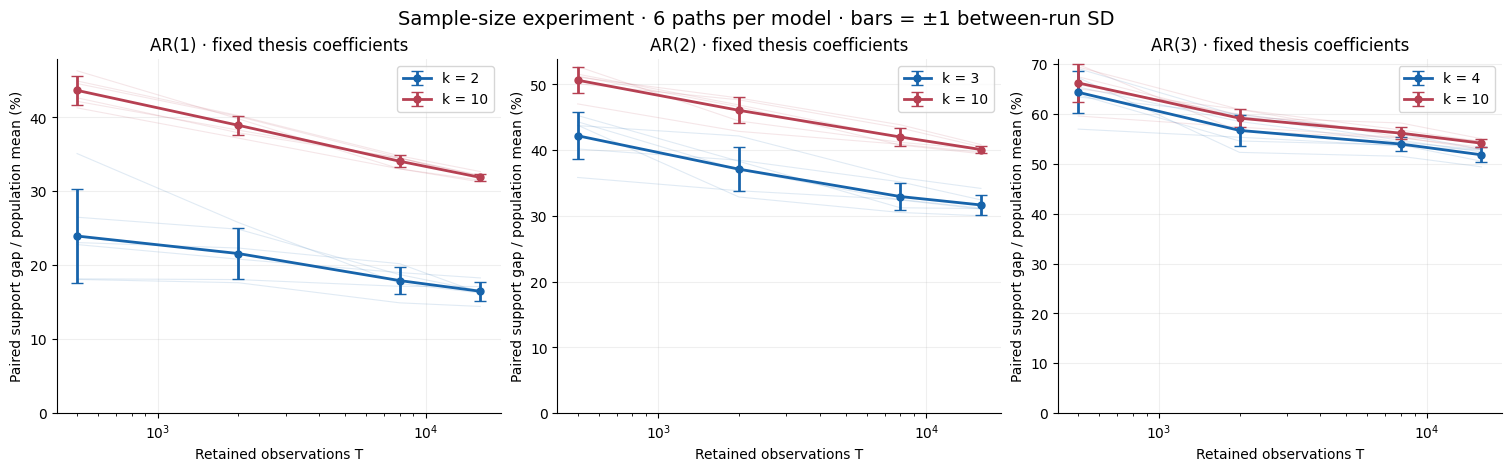

,p,k,T,replications,empirical_mean,empirical_sd_between_runs,mean_gap_percent,sd_gap_percent,mean_conditional_mc_se
0,1,2,500,6,3.5535,0.3126,23.9502,6.3387,0.0307
1,1,2,2000,6,3.6630,0.1735,21.5807,3.3917,0.0308
2,1,2,8000,6,3.8320,0.0866,17.9235,1.8360,0.0329
3,1,2,16000,6,3.8988,0.0659,16.4780,1.2643,0.0337
4,1,10,500,6,3.8782,0.1406,43.6485,1.9131,0.0257
5,1,10,2000,6,4.2050,0.0888,38.9229,1.2943,0.0251
6,1,10,8000,6,4.5411,0.0732,34.0626,0.8059,0.0277
7,1,10,16000,6,4.6920,0.0625,31.8802,0.5138,0.0284
8,2,3,500,6,4.8415,0.3138,42.2007,3.5589,0.0363
9,2,3,2000,6,5.2683,0.2409,37.1138,3.3921,0.0402


In [10]:
sample_rows = []
for p, process in processes.items():
    phi = process['phi']
    for replication in range(N_SAMPLE_REPLICATIONS):
        long_rng = np.random.default_rng(np.random.SeedSequence([SAMPLE_SEED, p, replication, 0]))
        long_x = simulate_uniform_ar(phi, max(T_GRID), BURNIN, HALF_WIDTH, rng=long_rng)
        for k in (p + 1, 10):
            directions = sphere_directions(k, M_SAMPLE, np.random.SeedSequence([SAMPLE_SEED, p, replication, k, 1]))
            generators = population_generators(phi, k)
            pop_widths = population_directional_widths(generators, directions)
            pop_mean = population_mean_width(generators)
            previous_widths = np.zeros(M_SAMPLE)
            for t in T_GRID:
                emp_widths = empirical_directional_widths(sliding_window_point_cloud(long_x[:t], k), directions)
                assert np.all(emp_widths >= previous_widths - 1e-12)
                gaps = pop_widths - emp_widths
                assert gaps.min() >= -1e-9
                gap = mc_summary(gaps)
                sample_rows.append({
                    'p': p, 'k': k, 'replication': replication, 'T': t, 'M': M_SAMPLE,
                    'empirical_mean': emp_widths.mean(), 'empirical_mc_se': mc_summary(emp_widths)['mc_se'],
                    'population_mean_H': pop_mean, 'paired_gap': gap['estimate'],
                    'paired_gap_mc_se': gap['mc_se'], 'paired_gap_percent': 100 * gap['estimate'] / pop_mean,
                })
                previous_widths = emp_widths
    print(f'Completed sample-size sweep for AR({p}) ({N_SAMPLE_REPLICATIONS} paths).')
sample_results = pd.DataFrame(sample_rows)
sample_summary = sample_results.groupby(['p', 'k', 'T'], as_index=False).agg(
    replications=('replication', 'size'), empirical_mean=('empirical_mean', 'mean'),
    empirical_sd_between_runs=('empirical_mean', 'std'),
    mean_gap_percent=('paired_gap_percent', 'mean'), sd_gap_percent=('paired_gap_percent', 'std'),
    mean_conditional_mc_se=('empirical_mc_se', 'mean'),
)
sample_results.to_csv(TABLES / 'sample_size_replications.csv', index=False)
sample_summary.to_csv(TABLES / 'sample_size_summary.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout='constrained')
for ax, p in zip(axes, processes):
    for k, color in [(p + 1, BLUE), (10, RED)]:
        subset = sample_results[(sample_results.p == p) & (sample_results.k == k)]
        for _, path in subset.groupby('replication'):
            ax.plot(path['T'], path.paired_gap_percent, color=color, alpha=0.13, lw=0.8)
        data = sample_summary[(sample_summary.p == p) & (sample_summary.k == k)]
        ax.errorbar(data['T'], data.mean_gap_percent, yerr=data.sd_gap_percent,
                    color=color, marker='o', ms=5, capsize=4, linewidth=2, label=f'k = {k}')
    ax.set(xscale='log', xlabel='Retained observations T', ylabel='Paired support gap / population mean (%)',
           title=f'AR({p}) · fixed thesis coefficients', ylim=(0, None))
    ax.legend()
fig.suptitle(f'Sample-size experiment · {N_SAMPLE_REPLICATIONS} paths per model · bars = ±1 between-run SD', fontsize=14)
show_and_save(fig, '04_sample_size_support_gap')
display(sample_summary.round(4))


## Preliminary interpretation and saved results

Mean width averages all directions, whereas minimum width singles out a
direction encoding the AR recurrence. A smooth or increasing mean-width
curve is therefore not evidence that the estimator is implemented incorrectly.
The white-noise calculation already rules out a universal horizontal
population plateau for this functional.

The numerical summary below is generated from the actual run. Three selected
models and a small repeated-sample experiment cannot establish a reliable AR
order selector. If a transition in the normalized curve is pursued, the next
experiment should define a selector in advance and assess it on many new
coefficient vectors, with BIC and minimum width as baselines. History
truncation and finite burn-in are additional numerical approximations.


In [11]:
lines = [
    '# Preliminary mean-width results', '',
    f'Main run: T={T_MAIN:,}, M={M_MAIN:,}, k=1,...,{max(K_VALUES)}, uniform [-1,1] innovations.',
    'The three thesis process seeds and zero-based replication indices were reproduced.', '',
]
for p in processes:
    data = main_results[main_results.p == p].set_index('k')
    first, last = data.loc[1], data.loc[10]
    lines.append(
        f'- AR({p}): empirical mean width {first.empirical_mean:.3f} at k=1 and '
        f'{last.empirical_mean:.3f} at k=10; population reference '
        f'{first.population_mean_H:.3f} and {last.population_mean_H:.3f}. '
        f'At k=10 the paired support gap is {last.paired_gap_percent:.1f}% '
        f'and the conditional MC SE is {last.empirical_mc_se:.4f}.'
    )
lines.extend(['', '**Sample-size experiment (new paths, fixed thesis coefficients):**', ''])
for p in processes:
    data = sample_summary[(sample_summary.p == p) & (sample_summary.k == 10)].set_index('T')
    lines.append(f'- AR({p}), k=10: average paired gap decreases from '
                 f'{data.loc[min(T_GRID), "mean_gap_percent"]:.1f}% at T={min(T_GRID):,} '
                 f'to {data.loc[max(T_GRID), "mean_gap_percent"]:.1f}% at T={max(T_GRID):,}.')
lines.extend([
    '', 'Increasing M reduces direction-integration error; it does not fill the missing population support. '
    'The raw mean-width curves do not inherit the minimum-width plateau and do not yet define an order selector.',
    '', f'The largest change in population mean width when doubling H={HISTORY:,} was '
    f'{truncation_results.absolute_change.max():.3g}. This is a numerical diagnostic, not a certified tail bound.',
])
summary_markdown = '\n'.join(lines)
(OUT / 'preliminary_findings.md').write_text(summary_markdown + '\n', encoding='utf-8')
display(Markdown(summary_markdown))

metadata = {
    'normalization': 'uniform probability measure on sphere; full widths',
    'window_convention': 'all valid backward windows, N_k=T-k+1, matching historical figure code',
    'historical_notebook_revision': '93c46bc3de4709951f5ee07dd59d545d869e0538',
    'process_specs': PROCESS_SPECS, 'T_main': T_MAIN, 'burnin': BURNIN,
    'innovation_half_width': HALF_WIDTH, 'K_values': K_VALUES.tolist(),
    'M_main': M_MAIN, 'direction_seed': DIRECTION_SEED, 'history': HISTORY,
    'M_grid': M_GRID, 'T_grid': T_GRID, 'M_sample': M_SAMPLE,
    'sample_replications': N_SAMPLE_REPLICATIONS, 'sample_seed': SAMPLE_SEED,
    'checks': checks, 'max_history_change': float(truncation_results.absolute_change.max()),
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'scipy': scipy.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__},
    'elapsed_seconds': perf_counter() - STARTED,
}
(OUT / 'run_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n', encoding='utf-8')
print(f'Figures, tables, settings, and summary saved to: {OUT}')
print(f'Elapsed time: {metadata["elapsed_seconds"]:.1f} seconds')


Figures, tables, settings, and summary saved to: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/mean_width
Elapsed time: 12.9 seconds


# Preliminary mean-width results

Main run: T=2,000, M=8,192, k=1,...,10, uniform [-1,1] innovations.
The three thesis process seeds and zero-based replication indices were reproduced.

- AR(1): empirical mean width 3.742 at k=1 and 4.218 at k=10; population reference 4.582 and 6.915. At k=10 the paired support gap is 39.0% and the conditional MC SE is 0.0084.
- AR(2): empirical mean width 5.666 at k=1 and 5.885 at k=10; population reference 8.134 and 10.127. At k=10 the paired support gap is 41.5% and the conditional MC SE is 0.0175.
- AR(3): empirical mean width 5.507 at k=1 and 5.686 at k=10; population reference 13.980 and 15.175. At k=10 the paired support gap is 62.2% and the conditional MC SE is 0.0139.

**Sample-size experiment (new paths, fixed thesis coefficients):**

- AR(1), k=10: average paired gap decreases from 43.6% at T=500 to 31.9% at T=16,000.
- AR(2), k=10: average paired gap decreases from 50.6% at T=500 to 40.1% at T=16,000.
- AR(3), k=10: average paired gap decreases from 66.2% at T=500 to 54.1% at T=16,000.

Increasing M reduces direction-integration error; it does not fill the missing population support. The raw mean-width curves do not inherit the minimum-width plateau and do not yet define an order selector.

The largest change in population mean width when doubling H=2,048 was 0. This is a numerical diagnostic, not a certified tail bound.

# Degree-two spherical harmonic experiments

This extension uses the **same three thesis realizations**, coefficient vectors,
backward windows, and population generators as the mean-width experiments above.
Run the notebook from the beginning. The new files are saved under
`outputs/mean_width/q2/`, including all plotted figures as PDF and PNG.

We investigate three scalar summaries and the associated directions:

| Summary | Population | Empirical |
|:--|:--|:--|
| Minimum degree-two component | $\lambda_{\min}(C_k)$ | $\lambda_{\min}(\widehat C_{k,T})$ |
| RMS degree-two magnitude | $\sqrt{2/[k(k+2)]}\|C_k\|_F$ | $\sqrt{2/[k(k+2)]}\|\widehat C_{k,T}\|_F$ |
| Minimum of the degree-0-plus-2 approximation | $2(Q_{0,k}+\lambda_{\min}(C_k))$ | $2(\widehat Q_{0,k,T}+\lambda_{\min}(\widehat C_{k,T}))$ |

Here $Q_2$ is a harmonic component of **half-width**, $Q_0=\overline w/2$,
and the sphere measure has mass one. Degree two is used only for $k\ge2$.
The spherical average of $Q_2$ is zero; its minimum is a signed shape summary,
not a width. The $Q_0+Q_2$ expression is a truncation approximation, not a
bound or an exact replacement for minimum width. Ratios to $Q_0$ measure
relative shape and remove overall multiplicative scale, but do not remove
arbitrary finite-sample distortion.

In population-versus-empirical plots, **orange is population**, **blue is
empirical**, and **green is the existing empirical minimum-width estimate**
where shown. Vertical markers indicate the known $p+1$, not estimated orders.


## Matrix estimators and Monte Carlo variance reduction

Write $H(u)=w_k(u)/2$, or use the empirical half-range
$\widehat H(u)=\widehat w_{k,T}(u)/2$. Then

$$Q_{2,k}(u)=u^\top C_k u,\qquad
C_k=\frac{k(k+2)}2\int H(u)\left(uu^\top-\frac{I_k}{k}\right)d\sigma(u).$$

For iid uniform directions, the direct Monte Carlo rule uses the sample
average in this formula. We also use the unbiased sample-covariance version

$$\widehat C^{\mathrm{centered}}_M
=\frac{k(k+2)}{2(M-1)}\sum_{m=1}^M
(H_m-\overline H)\left(U_mU_m^\top-\frac{I_k}{k}\right).$$

Since $\mathbb E[UU^\top]=I_k/k$, both estimators have the same expectation.
The $M-1$ correction is required when the same iid sample estimates
$\overline H$. Centering prevents a constant baseline from creating spurious
quadratic anisotropy through random directional imbalance. This correction is
for **iid Monte Carlo**, not deterministic angular quadrature. Eigenvalues,
norms, and normalized ratios are nonlinear and need not be unbiased at finite
$M$, even though the matrix estimators are unbiased.

For a population benchmark, let $b_j=a g_j^{(k)}$ denote the scaled generators,
$r_j=\|b_j\|$, $S=\sum_jr_j$, and
$\mu_k=\Gamma(k/2)/(\sqrt\pi\Gamma((k+1)/2))$. Direct integration gives

$$Q_{0,k}=\mu_k S,\qquad
C_k=\frac{\mu_k k(k+2)}{2(k+1)}
\left(\sum_{r_j>0}\frac{b_jb_j^\top}{r_j}-\frac{S}{k}I_k\right).$$

We compare history $H$ with $2H$ as a numerical diagnostic, without treating
agreement as a rigorous infinite-tail bound. The matrix derivation follows the
existing `output/pdf/ar_support_harmonics_summary_v6.tex` working notes.


In [12]:
Q2_STARTED = perf_counter()
Q2_OUT = OUT / 'q2'
Q2_FIGURES, Q2_TABLES = Q2_OUT / 'figures', Q2_OUT / 'tables'
for directory in (Q2_FIGURES, Q2_TABLES):
    directory.mkdir(parents=True, exist_ok=True)

Q2_K_VALUES = K_VALUES[K_VALUES >= 2]
Q2_SEED = 20260911
Q2_MAIN_M = 32_768
Q2_MAIN_BANKS = 3  # pooled main estimate: 98,304 independent directions
Q2_MC_GRID = [128, 512, 2_048, 8_192, 32_768]
Q2_MC_REPEATS = 8
Q2_SAMPLE_M = 8_192
Q2_SAMPLE_REPLICATIONS = 6
Q2_SAMPLE_T_GRID = T_GRID
Q2_PURPLE = '#8156ad'


def show_q2_figure(fig, name):
    fig.savefig(Q2_FIGURES / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(Q2_FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def symmetric_traceless(matrix):
    matrix = (matrix + matrix.T) / 2
    return matrix - np.trace(matrix) * np.eye(len(matrix)) / len(matrix)


def q2_matrix_from_widths(widths, directions, *, centered=True):
    """Full directional widths -> half-width harmonic (Q0, C).

    centered=True is the unbiased covariance rule for iid sphere samples.
    centered=False is the direct projection rule, also valid for an equally
    weighted deterministic quadrature. Both preserve symmetry and zero trace.
    """
    directions = np.asarray(directions, dtype=float)
    if directions.ndim != 2 or directions.shape[1] < 2:
        raise ValueError('Q2 requires directions in dimension k >= 2.')
    directions = validated_directions(directions, directions.shape[1])
    widths = np.asarray(widths, dtype=float)
    if widths.shape != (len(directions),) or len(widths) < 2 or not np.isfinite(widths).all():
        raise ValueError('Need at least two finite widths matching the directions.')
    k, m = directions.shape[1], len(directions)
    half_widths = widths / 2
    q0 = float(half_widths.mean())
    with threadpool_limits(limits=1, user_api='blas'):
        if centered:
            # E[(H-Hbar) UU^T] with divisor M-1 estimates Cov(H, UU^T).
            matrix = directions.T @ ((half_widths - q0)[:, None] * directions) / (m - 1)
        else:
            matrix = directions.T @ (half_widths[:, None] * directions) / m - q0 * np.eye(k) / k
    return q0, symmetric_traceless(k * (k + 2) * matrix / 2)


def population_q2(generators):
    generators = np.asarray(generators, dtype=float)
    if generators.ndim != 2 or generators.shape[1] < 2 or not np.isfinite(generators).all():
        raise ValueError('Need a finite generator matrix in dimension k >= 2.')
    k = generators.shape[1]
    lengths = np.linalg.norm(generators, axis=1)
    nonzero = lengths > 0  # avoid 0/0 for numerically zero tail terms
    active, lengths = generators[nonzero], lengths[nonzero]
    mu = sphere_abs_coordinate_mean(k)
    q0 = float(mu * lengths.sum())
    matrix = (active.T / lengths) @ active - lengths.sum() * np.eye(k) / k
    matrix = mu * k * (k + 2) / (2 * (k + 1)) * matrix
    return q0, symmetric_traceless(matrix)


def q2_descriptors(q0, matrix):
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    k = len(matrix)
    rms = np.sqrt(2 / (k * (k + 2))) * np.linalg.norm(matrix, 'fro')
    return {
        'q0': float(q0), 'min_q2': float(eigenvalues[0]), 'rms_q2': float(rms),
        'normalized_min_q2': float(eigenvalues[0] / q0),
        'normalized_rms_q2': float(rms / q0),
        'quadratic_min_width': float(2 * (q0 + eigenvalues[0])),
        'normalized_eigengap': float((eigenvalues[1] - eigenvalues[0]) / q0),
        'direction': eigenvectors[:, 0], 'eigenvalues': eigenvalues,
    }


def direction_angle_degrees(left, right):
    """Angle between unoriented unit directions (sign is irrelevant)."""
    return float(np.degrees(np.arccos(np.clip(abs(left @ right), 0, 1))))


def scalar_descriptors(descriptors):
    return {key: value for key, value in descriptors.items() if key not in ('direction', 'eigenvalues')}


def matrix_error_metrics(q0_hat, matrix_hat, q0, matrix):
    """Full matrix discrepancies; scalar minima can hide other shape errors."""
    scale = np.linalg.norm(matrix, 'fro')
    return {
        'matrix_error_relative': float(np.linalg.norm(matrix_hat - matrix, 'fro') / scale),
        'normalized_matrix_error_relative': float(np.linalg.norm(matrix_hat / q0_hat - matrix / q0, 'fro') / (scale / q0)),
        'operator_error_over_q0': float(np.linalg.norm(matrix_hat - matrix, 2) / q0),
    }


## Independent checks of the degree-two projection

In two dimensions, a half-width test function
$3+0.7\cos(2\theta)-0.4\sin(2\theta)+0.2\cos(4\theta)$ has the exact
degree-two matrix $\begin{pmatrix}0.7&-0.4\\-0.4&-0.7\end{pmatrix}$.
This checks normalization and rejection of degrees zero and four. A cube has
zero degree-two component despite having a nonconstant width function, which
also illustrates information lost when truncating to $Q_2$.

Additional checks cover matrix rotation equivariance, invariance of centered
estimation to a constant width offset, the RMS identity, and population
generator integration. The Monte Carlo estimator is also checked against
repeated independent samples of a known quadratic test function.


In [13]:
angles = np.arange(16_384) * (2 * np.pi / 16_384)
circle_q2 = np.column_stack([np.cos(angles), np.sin(angles)])
test_h = 3 + 0.7 * np.cos(2 * angles) - 0.4 * np.sin(2 * angles) + 0.2 * np.cos(4 * angles)
expected_C = np.array([[0.7, -0.4], [-0.4, -0.7]])
test_q0, test_C = q2_matrix_from_widths(2 * test_h, circle_q2, centered=False)
np.testing.assert_allclose(test_C, expected_C, atol=2e-13)
assert abs(test_q0 - 3) < 1e-13
rms_integral = np.mean(np.einsum('mi,ij,mj->m', circle_q2, test_C, circle_q2) ** 2)
assert abs(rms_integral - 2 * np.linalg.norm(test_C, 'fro')**2 / (2 * 4)) < 1e-13

q2_test_rng = np.random.default_rng(49081)
test_U = sphere_directions(3, 2000, q2_test_rng)
test_cloud = q2_test_rng.normal(size=(40, 3))
test_W = empirical_directional_widths(test_cloud, test_U)
_, centered_C = q2_matrix_from_widths(test_W, test_U)
_, offset_C = q2_matrix_from_widths(test_W + 100, test_U)
np.testing.assert_allclose(centered_C, offset_C, atol=1e-12)
rotation, _ = np.linalg.qr(q2_test_rng.normal(size=(3, 3)))
_, rotated_C = q2_matrix_from_widths(test_W, test_U @ rotation)
np.testing.assert_allclose(rotated_C, rotation.T @ centered_C @ rotation, atol=1e-12)
assert abs(np.trace(centered_C)) < 1e-12
_, constant_C = q2_matrix_from_widths(np.full(len(test_U), 8.0), test_U)
np.testing.assert_allclose(constant_C, 0, atol=1e-14)
for k in Q2_K_VALUES:
    _, cube_C = population_q2(population_generators([0.0], int(k), history=32))
    np.testing.assert_allclose(cube_C, 0, atol=1e-13)

# Independent angular integration of the AR(1) population generator result.
test_G = population_generators(processes[1]['phi'], 2)
pop_q0_check, pop_C_check = population_q2(test_G)
angular_q0, angular_C = q2_matrix_from_widths(population_directional_widths(test_G, circle_q2), circle_q2, centered=False)
angular_error = float(np.linalg.norm(angular_C - pop_C_check, 'fro'))
assert angular_error < 2e-6

# Monte Carlo covariance correction checked on a known degree-two signal.
replicate_C = []
for repetition in range(128):
    directions = sphere_directions(2, 1024, q2_test_rng)
    known_h = 3 + np.einsum('mi,ij,mj->m', directions, expected_C, directions)
    _, matrix = q2_matrix_from_widths(2 * known_h, directions)
    replicate_C.append(matrix)
replicate_C = np.asarray(replicate_C)
check_mean, check_se = replicate_C.mean(axis=0), replicate_C.std(axis=0, ddof=1) / np.sqrt(len(replicate_C))
assert np.all(abs(check_mean - expected_C) <= 6 * check_se + 1e-12)
q2_checks = {'quadratic_projection_error': float(np.linalg.norm(test_C - expected_C)),
             'population_angular_matrix_error': angular_error,
             'known_signal_mc_mean_error': float(np.linalg.norm(check_mean - expected_C)),
             'centered_constant_offset_error': float(np.linalg.norm(offset_C - centered_C))}
display(pd.Series(q2_checks, name='absolute error'))
print('All Q2 projection, invariance, and Monte Carlo checks passed.')


All Q2 projection, invariance, and Monte Carlo checks passed.


quadratic_projection_error         2.794941e-14
population_angular_matrix_error    2.805012e-08
known_signal_mc_mean_error         5.487669e-03
centered_constant_offset_error     8.776746e-16
Name: absolute error, dtype: float64

## Experiment 4: population and empirical degree two across dimension

For each of the three fixed thesis series and each $k=2,\ldots,10$, pool three
independent banks of 32,768 directions. The main empirical estimate therefore
uses **98,304 directions**. Independent bank estimates are also retained;
the blue bands below span their minimum and maximum and are a diagnostic of
integration sensitivity, **not a confidence interval**. These bands describe
individual 32,768-direction calculations, while the line uses the pooled bank.

No process coefficients are estimated here. The population matrix uses known
coefficients solely as a benchmark. We also examine the entire normalized
eigenvalue spectrum; agreement of only the smallest eigenvalue can conceal
differences elsewhere in the matrix.


In [14]:
q2_rows, q2_bank_rows, q2_spectrum_rows, q2_direction_rows = [], [], [], []
q2_history_rows, q2_matrices = [], {}
for p, process in processes.items():
    phi, x = process['phi'], process['x']
    for k_value in Q2_K_VALUES:
        k = int(k_value)
        generators = population_generators(phi, k)
        pop_q0, pop_C = population_q2(generators)
        pop = q2_descriptors(pop_q0, pop_C)
        q0_2h, C_2h = population_q2(population_generators(phi, k, 2 * HISTORY))
        history_error = float(np.linalg.norm(C_2h - pop_C, 'fro'))
        assert history_error <= 1e-10 * max(1, np.linalg.norm(pop_C, 'fro'))
        q2_history_rows.append({'p': p, 'k': k, 'H': HISTORY, 'matrix_H_to_2H_error': history_error,
                                'q0_H_to_2H_error': abs(q0_2h - pop_q0)})
        cloud = sliding_window_point_cloud(x, k)
        all_directions, all_widths, individual_matrices = [], [], []
        for bank in range(Q2_MAIN_BANKS):
            directions = sphere_directions(k, Q2_MAIN_M, np.random.SeedSequence([Q2_SEED, 0, p, k, bank]))
            widths = empirical_directional_widths(cloud, directions)
            empirical_q0, empirical_C = q2_matrix_from_widths(widths, directions)
            desc = q2_descriptors(empirical_q0, empirical_C)
            q2_bank_rows.append({'p': p, 'k': k, 'bank': bank, 'M': Q2_MAIN_M, **scalar_descriptors(desc)})
            all_directions.append(directions)
            all_widths.append(widths)
            individual_matrices.append(empirical_C)
        pooled_U, pooled_W = np.vstack(all_directions), np.concatenate(all_widths)
        empirical_q0, empirical_C = q2_matrix_from_widths(pooled_W, pooled_U)
        empirical = q2_descriptors(empirical_q0, empirical_C)
        matrix_metrics = matrix_error_metrics(empirical_q0, empirical_C, pop_q0, pop_C)
        main_row = main_results[(main_results.p == p) & (main_results.k == k)].iloc[0]
        q2_rows.append({
            'p': p, 'k': k, 'T': len(x), 'M_pooled': len(pooled_W),
            **{'population_' + key: value for key, value in scalar_descriptors(pop).items()},
            **{'empirical_' + key: value for key, value in scalar_descriptors(empirical).items()},
            **matrix_metrics, 'empirical_full_minimum_width': float(main_row.empirical_minimum),
            'thesis_population_minimum_plateau': float(main_row.population_minimum_plateau),
        })
        # Estimated integration uncertainty of the pooled reference, from independent banks.
        bank_array = np.asarray(individual_matrices)
        reference_noise_fro = float(np.sqrt(np.sum(bank_array.var(axis=0, ddof=1)) / Q2_MAIN_BANKS))
        q2_matrices[p, k] = {'population_q0': pop_q0, 'population_C': pop_C,
                             'empirical_q0': empirical_q0, 'empirical_C': empirical_C,
                             'reference_noise_fro': reference_noise_fro,
                             'generators': generators}
        for eigen_index, (population_eigenvalue, empirical_eigenvalue) in enumerate(zip(pop['eigenvalues'], empirical['eigenvalues']), 1):
            q2_spectrum_rows.append({'p': p, 'k': k, 'eigen_index': eigen_index,
                                     'population_eigenvalue': population_eigenvalue,
                                     'empirical_eigenvalue': empirical_eigenvalue,
                                     'population_normalized_eigenvalue': population_eigenvalue / pop_q0,
                                     'empirical_normalized_eigenvalue': empirical_eigenvalue / empirical_q0})
        if k == p + 1:
            ar_normal = np.r_[1.0, -phi]
            ar_normal /= np.linalg.norm(ar_normal)
            q2_direction_rows.append({
                'p': p, 'k': k, 'empirical_vs_population_q2_degrees': direction_angle_degrees(empirical['direction'], pop['direction']),
                'population_q2_vs_ar_normal_degrees': direction_angle_degrees(pop['direction'], ar_normal),
                'empirical_q2_vs_ar_normal_degrees': direction_angle_degrees(empirical['direction'], ar_normal),
                'population_normalized_eigengap': pop['normalized_eigengap'],
                'empirical_normalized_eigengap': empirical['normalized_eigengap'],
            })
    print(f'Completed Q2 dimension sweep for AR({p}).')
q2_results = pd.DataFrame(q2_rows)
q2_bank_results = pd.DataFrame(q2_bank_rows)
q2_spectra = pd.DataFrame(q2_spectrum_rows)
q2_directions = pd.DataFrame(q2_direction_rows)
q2_history = pd.DataFrame(q2_history_rows)
for frame, name in [(q2_results, 'dimension_descriptors'), (q2_bank_results, 'independent_direction_banks'),
                    (q2_spectra, 'eigenvalue_spectra'), (q2_directions, 'directions_at_known_order'),
                    (q2_history, 'population_history_check')]:
    frame.to_csv(Q2_TABLES / f'{name}.csv', index=False)
np.savez_compressed(Q2_OUT / 'matrices.npz', **{
    f'p{p}_k{k}_{name}': values[name]
    for (p, k), values in q2_matrices.items()
    for name in ('population_C', 'empirical_C', 'population_q0', 'empirical_q0')
})
display(q2_results[q2_results.k == q2_results.p + 1][[
    'p', 'k', 'population_min_q2', 'empirical_min_q2',
    'population_normalized_min_q2', 'empirical_normalized_min_q2',
    'matrix_error_relative', 'normalized_matrix_error_relative',
]].round(5))


Completed Q2 dimension sweep for AR(1).
Completed Q2 dimension sweep for AR(2).
Completed Q2 dimension sweep for AR(3).


,p,k,population_min_q2,empirical_min_q2,population_normalized_min_q2,empirical_normalized_min_q2,matrix_error_relative,normalized_matrix_error_relative
0,1,2,-0.96694,-0.73457,-0.41847,-0.39728,0.24725,0.08241
10,2,3,-2.26033,-1.57341,-0.53878,-0.56077,0.31548,0.21109
20,3,4,-3.95146,-1.47344,-0.55416,-0.52271,0.72949,0.40200


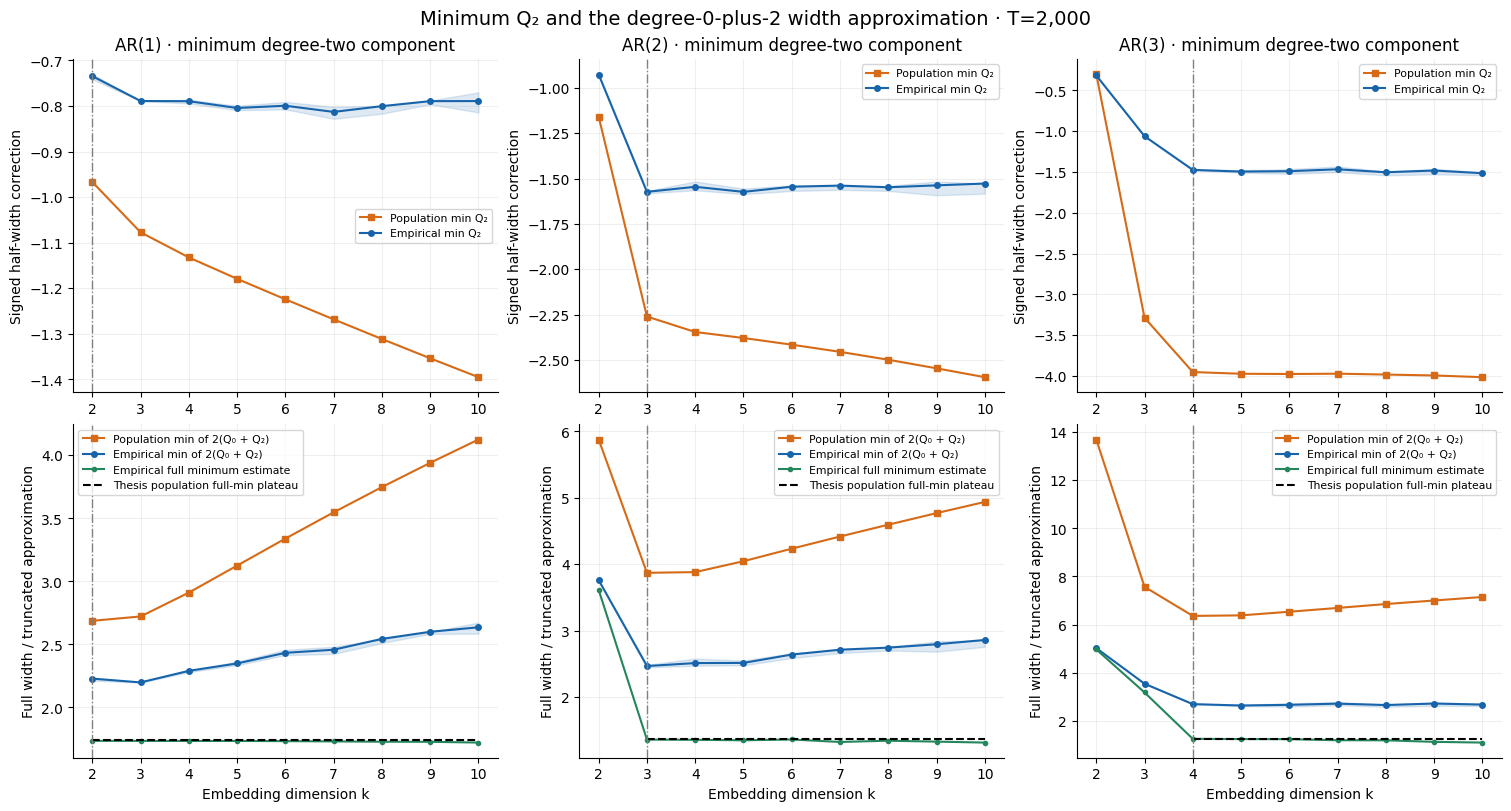

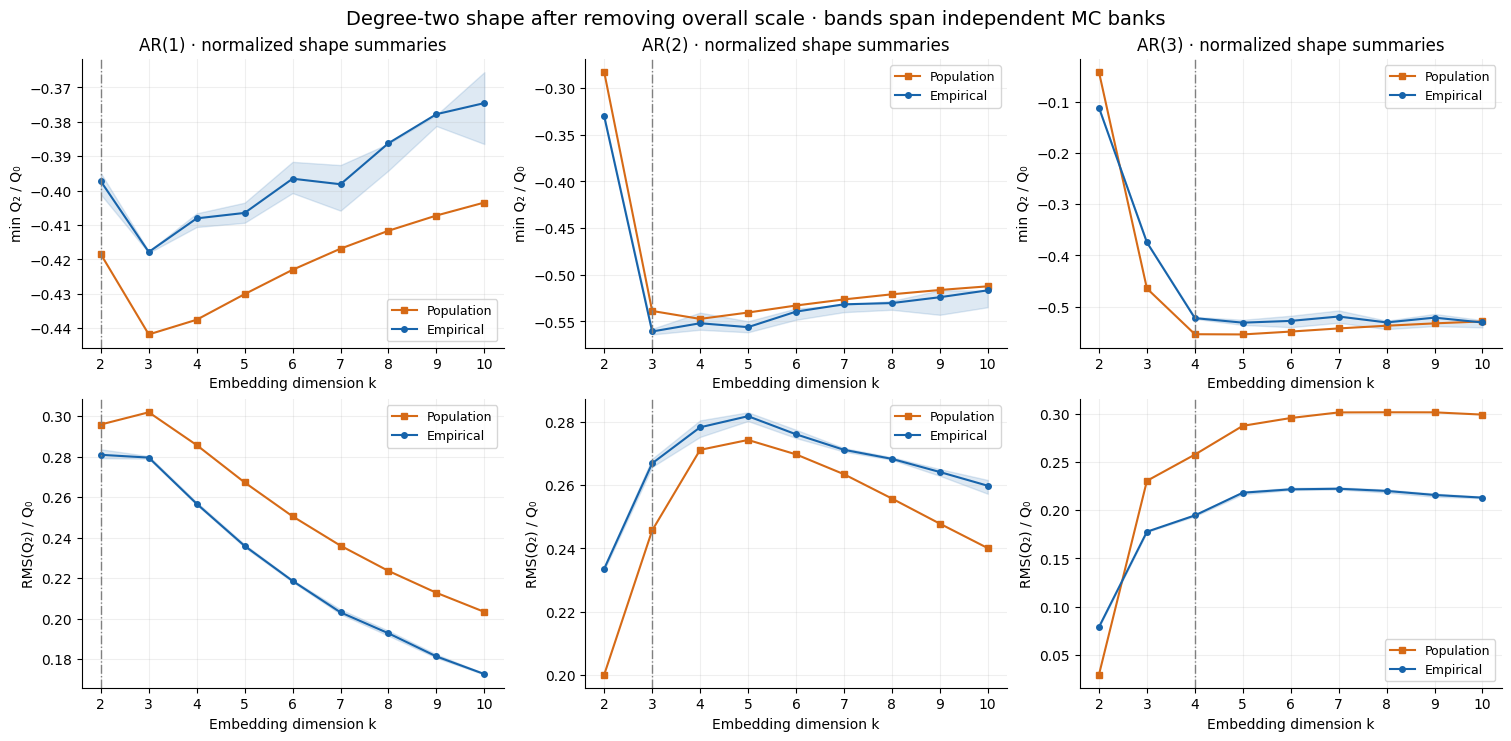

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for column, p in enumerate(processes):
    data = q2_results[q2_results.p == p]
    bank_range = q2_bank_results[q2_bank_results.p == p].groupby('k').agg(
        min_low=('min_q2', 'min'), min_high=('min_q2', 'max'),
        width_low=('quadratic_min_width', 'min'), width_high=('quadratic_min_width', 'max'))
    ax = axes[0, column]
    ax.plot(data.k, data.population_min_q2, 's-', color=ORANGE, ms=4, label='Population min Q₂')
    ax.plot(data.k, data.empirical_min_q2, 'o-', color=BLUE, ms=4, label='Empirical min Q₂')
    ax.fill_between(bank_range.index, bank_range.min_low, bank_range.min_high, color=BLUE, alpha=.14)
    ax.set(title=f'AR({p}) · minimum degree-two component', ylabel='Signed half-width correction')
    ax = axes[1, column]
    ax.plot(data.k, data.population_quadratic_min_width, 's-', color=ORANGE, ms=4, label='Population min of 2(Q₀ + Q₂)')
    ax.plot(data.k, data.empirical_quadratic_min_width, 'o-', color=BLUE, ms=4, label='Empirical min of 2(Q₀ + Q₂)')
    ax.fill_between(bank_range.index, bank_range.width_low, bank_range.width_high, color=BLUE, alpha=.14)
    ax.plot(data.k, data.empirical_full_minimum_width, '.-', color=GREEN, label='Empirical full minimum estimate')
    ax.plot(data.k, data.thesis_population_minimum_plateau, '--', color='black', label='Thesis population full-min plateau')
    ax.set(ylabel='Full width / truncated approximation', xlabel='Embedding dimension k')
    for ax in axes[:, column]:
        ax.axvline(p + 1, color='0.5', linestyle='-.', linewidth=1)
        ax.set_xticks(Q2_K_VALUES)
        ax.legend(fontsize=7.8)
fig.suptitle('Minimum Q₂ and the degree-0-plus-2 width approximation · T=2,000', fontsize=14)
show_q2_figure(fig, '01_min_q2_and_width_approximation')

fig, axes = plt.subplots(2, 3, figsize=(15, 7.3), layout='constrained')
for column, p in enumerate(processes):
    data = q2_results[q2_results.p == p]
    banks = q2_bank_results[q2_bank_results.p == p]
    for row, key, ylabel in [(0, 'normalized_min_q2', 'min Q₂ / Q₀'), (1, 'normalized_rms_q2', 'RMS(Q₂) / Q₀')]:
        spread = banks.groupby('k')[key].agg(['min', 'max'])
        ax = axes[row, column]
        ax.plot(data.k, data['population_' + key], 's-', color=ORANGE, ms=4, label='Population')
        ax.plot(data.k, data['empirical_' + key], 'o-', color=BLUE, ms=4, label='Empirical')
        ax.fill_between(spread.index, spread['min'], spread['max'], color=BLUE, alpha=.14)
        ax.axvline(p + 1, color='0.5', linestyle='-.', linewidth=1)
        ax.set(xlabel='Embedding dimension k', ylabel=ylabel, xticks=Q2_K_VALUES)
        ax.legend(fontsize=9)
    axes[0, column].set_title(f'AR({p}) · normalized shape summaries')
fig.suptitle('Degree-two shape after removing overall scale · bands span independent MC banks', fontsize=14)
show_q2_figure(fig, '02_normalized_q2_shape')


### Spectra and minimizing directions

We inspect the normalized eigenvalue spectrum at the known $k=p+1$ and at
$k=10$. Angles to the AR recurrence normal are reported only at $k=p+1$;
at higher dimensions, several shifted recurrence directions would be possible.
An angle between population and empirical $Q_2$ minimizers measures **shape
estimation**, whereas the angle to $(1,-\phi_1,\ldots,-\phi_p)$ measures
agreement with the AR relation. These are different questions.

Eigenvectors are compared up to sign. A small gap between the two lowest
eigenvalues makes an individual minimizing direction unstable; inspect the
reported normalized eigengap before interpreting an angle. The dimension
used here is known, so these direction comparisons do not establish order
recovery.


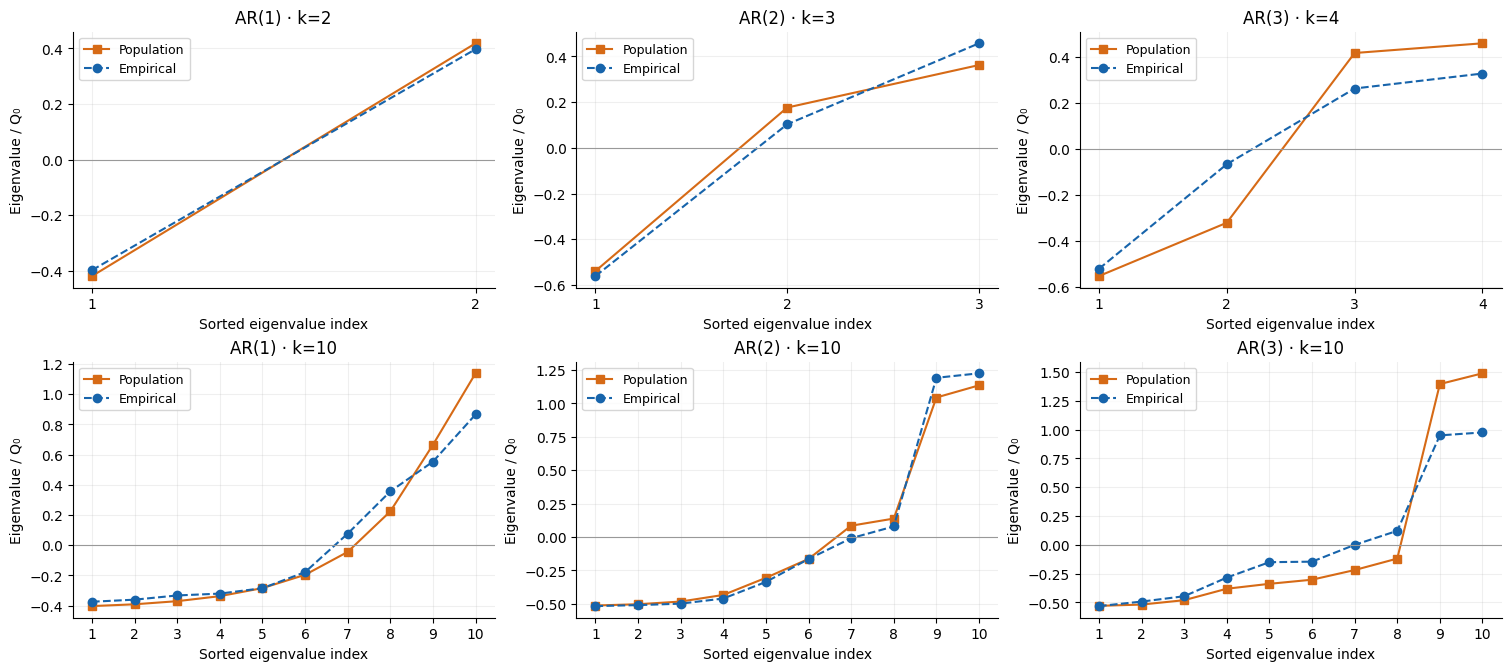

,p,k,empirical_vs_population_q2_degrees,population_q2_vs_ar_normal_degrees,empirical_q2_vs_ar_normal_degrees,population_normalized_eigengap,empirical_normalized_eigengap
0,1,2,1.9123,11.0260,12.9383,0.8369,0.7946
1,2,3,2.7347,8.7409,11.4515,0.7152,0.6641
2,3,4,3.1615,10.1309,10.1202,0.2321,0.4554


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.6), layout='constrained')
for column, p in enumerate(processes):
    for row, k in enumerate((p + 1, 10)):
        data = q2_spectra[(q2_spectra.p == p) & (q2_spectra.k == k)]
        ax = axes[row, column]
        ax.plot(data.eigen_index, data.population_normalized_eigenvalue, 's-', color=ORANGE, label='Population')
        ax.plot(data.eigen_index, data.empirical_normalized_eigenvalue, 'o--', color=BLUE, label='Empirical')
        ax.axhline(0, color='0.6', linewidth=.8)
        ax.set(title=f'AR({p}) · k={k}', xlabel='Sorted eigenvalue index', ylabel='Eigenvalue / Q₀', xticks=np.arange(1, k + 1))
        ax.legend(fontsize=9)
show_q2_figure(fig, '03_normalized_eigenvalue_spectra')
display(q2_directions.round(4))


## Experiment 5: does Monte Carlo recover the matrix?

Hold the time series fixed. At $k=p+1$ and $k=10$, draw eight new independent
banks, each with 32,768 directions, and use nested prefixes of length
128, 512, 2,048, 8,192, and 32,768. Compare the direct and centered rules on
**the same directions**. Population widths are evaluated on those directions
as well, so their integration error has an analytic matrix benchmark.

For the empirical matrix, the pooled main estimate above is an **independent
98,304-direction numerical reference**, not exact truth. Its approximate
integration-noise scale is estimated from the three independent main banks
and plotted as a dotted line. Empirical errors approaching that level cannot
be interpreted as exact integration errors. All plotted errors are Frobenius
matrix errors divided by the appropriate reference $Q_0$, root-mean-squared
over the eight banks. They are not time-series sampling errors or confidence
intervals. The faint $M^{-1/2}$ line is a visual reference, not a fitted rate.


Completed independent Q2 Monte Carlo checks: AR(1), k=2.
Completed independent Q2 Monte Carlo checks: AR(1), k=10.
Completed independent Q2 Monte Carlo checks: AR(2), k=3.
Completed independent Q2 Monte Carlo checks: AR(2), k=10.
Completed independent Q2 Monte Carlo checks: AR(3), k=4.
Completed independent Q2 Monte Carlo checks: AR(3), k=10.


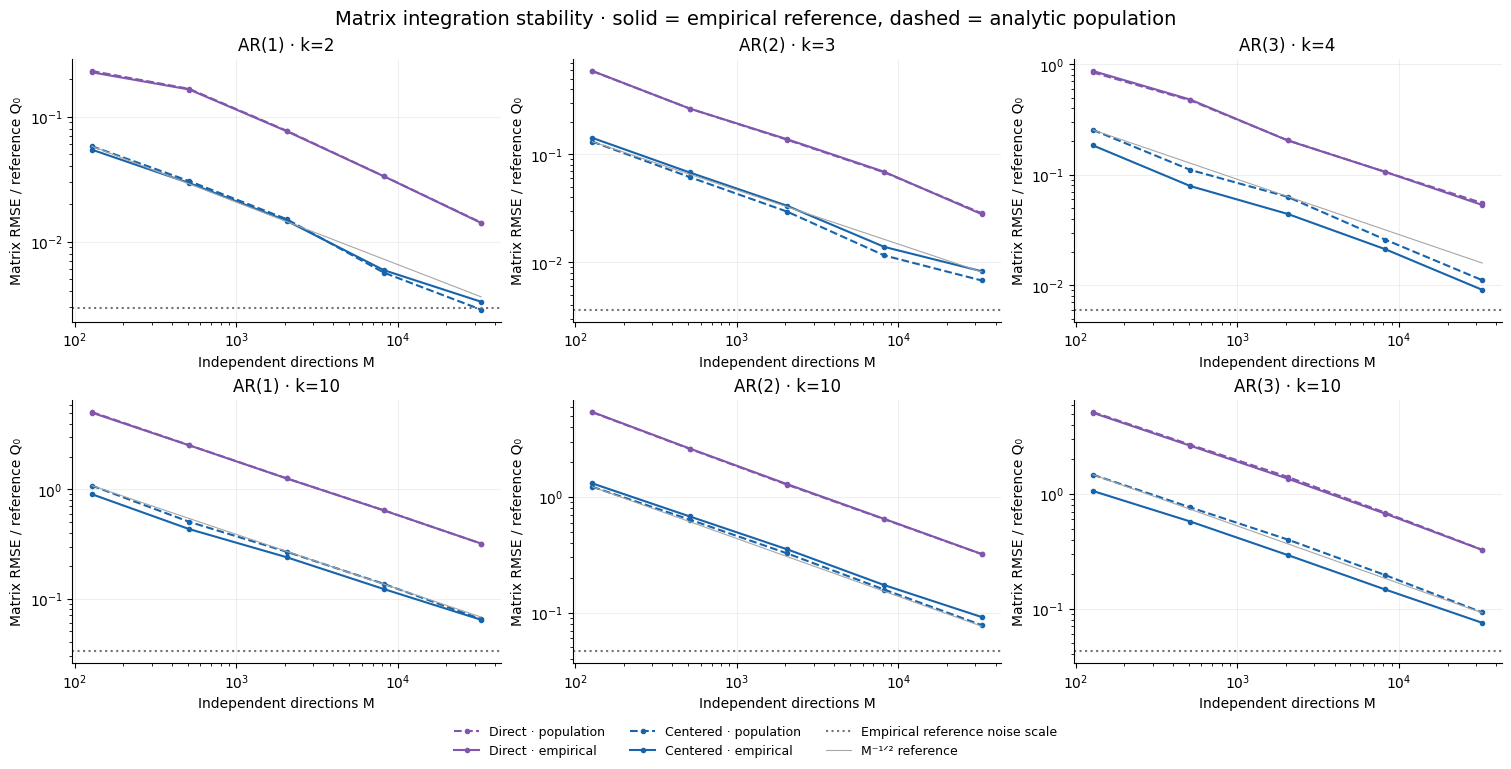

,p,k,M,target,estimator,matrix_rmse_over_q0,operator_rmse_over_q0,min_q2_rmse_over_q0,normalized_min_mean,normalized_min_sd,direction_error_median_degrees,reference_noise_over_q0
16,1,2,32768,empirical,centered,0.00330,0.00234,0.00201,-0.39947,0.00182,0.07330,0.00297
18,1,2,32768,population,centered,0.00286,0.00202,0.00159,-0.41919,0.00179,0.04054,0.00000
36,1,10,32768,empirical,centered,0.06393,0.03516,0.00959,-0.38047,0.00800,27.83594,0.03329
38,1,10,32768,population,centered,0.06475,0.03554,0.01079,-0.41144,0.00788,26.71771,0.00000
56,2,3,32768,empirical,centered,0.00826,0.00637,0.00471,-0.55681,0.00356,0.16424,0.00365
58,2,3,32768,population,centered,0.00679,0.00524,0.00365,-0.53747,0.00401,0.19092,0.00000
76,2,10,32768,empirical,centered,0.09159,0.05456,0.01923,-0.53467,0.00910,30.99956,0.04688
78,2,10,32768,population,centered,0.07796,0.04708,0.01651,-0.52614,0.00961,36.15278,0.00000
96,3,4,32768,empirical,centered,0.00911,0.00672,0.00342,-0.52082,0.00332,0.34918,0.00603
98,3,4,32768,population,centered,0.01113,0.00830,0.00306,-0.55313,0.00348,0.77677,0.00000


In [17]:
q2_mc_rows = []
for p, process in processes.items():
    for k in (p + 1, 10):
        reference = q2_matrices[p, k]
        cloud = sliding_window_point_cloud(process['x'], k)
        for repetition in range(Q2_MC_REPEATS):
            directions = sphere_directions(k, max(Q2_MC_GRID), np.random.SeedSequence([Q2_SEED, 1, p, k, repetition]))
            empirical_widths = empirical_directional_widths(cloud, directions)
            population_widths = population_directional_widths(reference['generators'], directions)
            for m in Q2_MC_GRID:
                for target, widths in [('empirical', empirical_widths), ('population', population_widths)]:
                    q0_ref, C_ref = reference[target + '_q0'], reference[target + '_C']
                    desc_ref = q2_descriptors(q0_ref, C_ref)
                    for estimator, centered in [('direct', False), ('centered', True)]:
                        q0_mc, C_mc = q2_matrix_from_widths(widths[:m], directions[:m], centered=centered)
                        desc = q2_descriptors(q0_mc, C_mc)
                        q2_mc_rows.append({
                            'p': p, 'k': k, 'repetition': repetition, 'M': m, 'target': target, 'estimator': estimator,
                            'matrix_error_over_q0': np.linalg.norm(C_mc - C_ref, 'fro') / q0_ref,
                            'operator_error_over_q0': np.linalg.norm(C_mc - C_ref, 2) / q0_ref,
                            'min_q2_error_over_q0': (desc['min_q2'] - desc_ref['min_q2']) / q0_ref,
                            'normalized_min_q2': desc['normalized_min_q2'],
                            'direction_error_degrees': direction_angle_degrees(desc['direction'], desc_ref['direction']),
                            'reference_noise_over_q0': reference['reference_noise_fro'] / q0_ref if target == 'empirical' else 0,
                        })
        print(f'Completed independent Q2 Monte Carlo checks: AR({p}), k={k}.')
q2_mc_results = pd.DataFrame(q2_mc_rows)
q2_mc_summary = q2_mc_results.groupby(['p', 'k', 'M', 'target', 'estimator'], as_index=False).agg(
    matrix_rmse_over_q0=('matrix_error_over_q0', lambda values: np.sqrt(np.mean(values**2))),
    operator_rmse_over_q0=('operator_error_over_q0', lambda values: np.sqrt(np.mean(values**2))),
    min_q2_rmse_over_q0=('min_q2_error_over_q0', lambda values: np.sqrt(np.mean(values**2))),
    normalized_min_mean=('normalized_min_q2', 'mean'), normalized_min_sd=('normalized_min_q2', 'std'),
    direction_error_median_degrees=('direction_error_degrees', 'median'),
    reference_noise_over_q0=('reference_noise_over_q0', 'first'),
)
q2_mc_results.to_csv(Q2_TABLES / 'mc_stability_replications.csv', index=False)
q2_mc_summary.to_csv(Q2_TABLES / 'mc_stability_summary.csv', index=False)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.6), layout='constrained')
for column, p in enumerate(processes):
    for row, k in enumerate((p + 1, 10)):
        ax = axes[row, column]
        for estimator, color in [('direct', Q2_PURPLE), ('centered', BLUE)]:
            for target, style in [('population', '--'), ('empirical', '-')]:
                data = q2_mc_summary[(q2_mc_summary.p == p) & (q2_mc_summary.k == k)
                                     & (q2_mc_summary.estimator == estimator) & (q2_mc_summary.target == target)]
                ax.plot(data.M, data.matrix_rmse_over_q0, style, color=color, marker='o', ms=3,
                        label=f'{estimator.capitalize()} · {target}')
        ref = q2_matrices[p, k]
        ax.axhline(ref['reference_noise_fro'] / ref['empirical_q0'], color='0.45', ls=':', label='Empirical reference noise scale')
        guide = q2_mc_summary[(q2_mc_summary.p == p) & (q2_mc_summary.k == k)
                              & (q2_mc_summary.estimator == 'centered') & (q2_mc_summary.target == 'population')]
        ax.plot(guide.M, guide.matrix_rmse_over_q0.iloc[0] * np.sqrt(guide.M.iloc[0] / guide.M),
                color='0.65', lw=.8, label='M⁻¹ᐟ² reference')
        ax.set(xscale='log', yscale='log', xlabel='Independent directions M', ylabel='Matrix RMSE / reference Q₀',
               title=f'AR({p}) · k={k}')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, frameon=False, fontsize=9)
fig.suptitle('Matrix integration stability · solid = empirical reference, dashed = analytic population', fontsize=14)
show_q2_figure(fig, '04_monte_carlo_matrix_stability')
display(q2_mc_summary[(q2_mc_summary.M == max(Q2_MC_GRID)) & (q2_mc_summary.estimator == 'centered')].round(5))


## Experiment 6: sample-size effects on raw and normalized quadratic shape

Use the same six fixed-coefficient innovation streams and nested sample sizes
as Experiment 3. Each process/dimension/replication uses one fixed bank of
8,192 directions across sample sizes. The selected dimensions are $p+1$ and
10. A paired population Monte Carlo calculation on the same directions is
saved to measure the scale of integration noise separately.

Compare both the raw matrix $\widehat C-C$ and the normalized shape matrix
$\widehat C/\widehat Q_0-C/Q_0$. Report scalar minima, RMS magnitudes,
truncated minimum widths, and minimizing-direction errors too. Matrix errors
are divided by the Frobenius norm of the corresponding population target.
Since these three population matrices are nonzero, the relative errors are
well defined. The sample paths and direction banks are independent between
replications; error bars are **one between-run sample SD**, not confidence
intervals. Unlike empirical directional widths, $Q_2$ summaries need not be
monotone in sample size.


Completed Q2 sample-size sweep for AR(1).
Completed Q2 sample-size sweep for AR(2).
Completed Q2 sample-size sweep for AR(3).


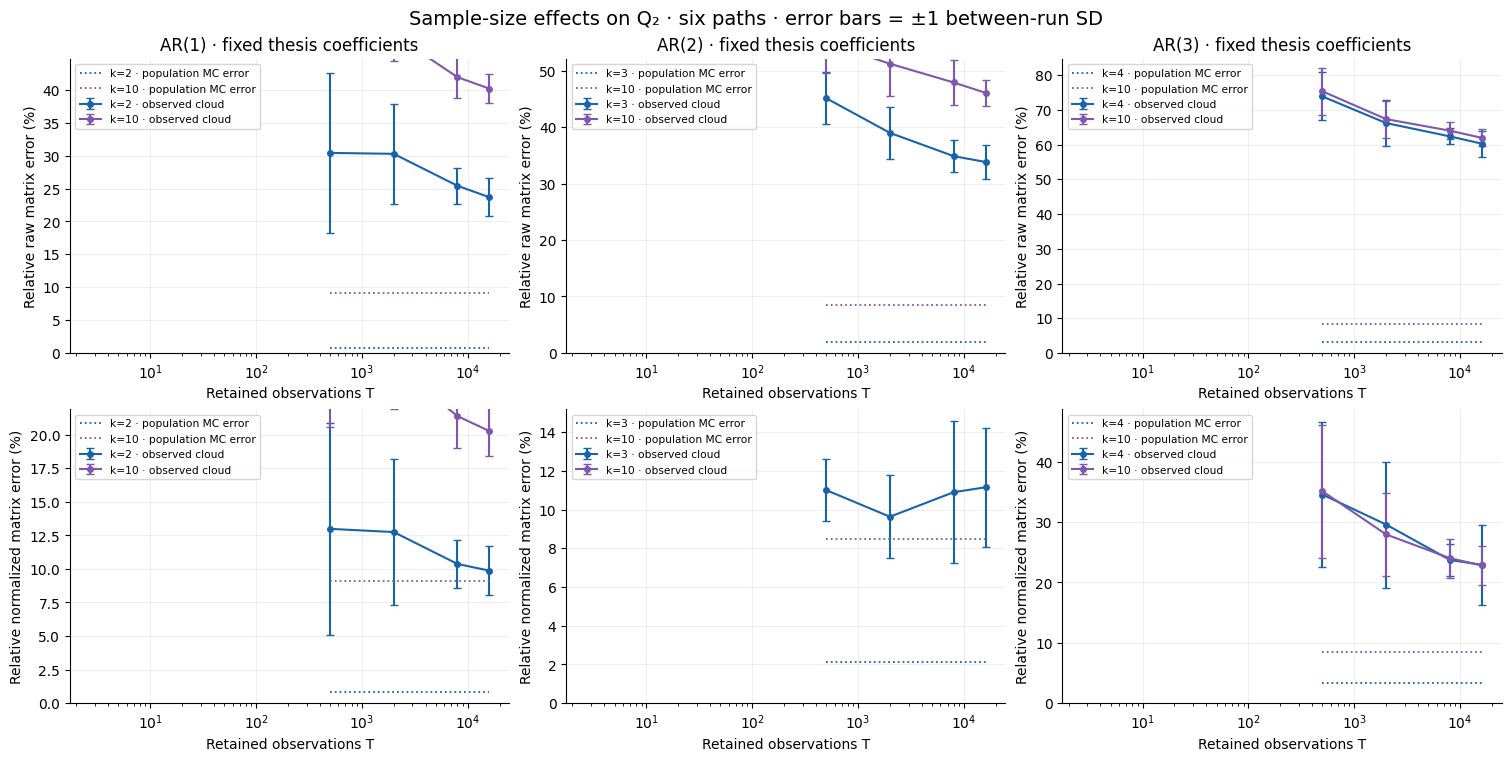

,p,k,T,raw_matrix_error_mean,normalized_matrix_error_mean,direction_to_population_q2_mean,direction_to_ar_normal_mean
0,1,2,500,0.3041,0.1299,2.1226,13.1485
1,1,2,2000,0.3027,0.1275,1.5594,12.5854
2,1,2,8000,0.2541,0.1037,1.6220,12.6480
3,1,2,16000,0.2367,0.0987,1.4501,12.4761
8,2,3,500,0.4510,0.1101,2.0777,10.2797
9,2,3,2000,0.3897,0.0963,2.1933,10.5761
10,2,3,8000,0.3485,0.1090,2.0135,10.6141
11,2,3,16000,0.3381,0.1115,2.0579,10.6198
16,3,4,500,0.7387,0.3457,3.2125,11.6089
17,3,4,2000,0.6620,0.2959,3.0607,11.5513


In [18]:
q2_sample_rows = []
for p, process in processes.items():
    phi = process['phi']
    for replication in range(Q2_SAMPLE_REPLICATIONS):
        rng = np.random.default_rng(np.random.SeedSequence([SAMPLE_SEED, p, replication, 0]))
        long_x = simulate_uniform_ar(phi, max(Q2_SAMPLE_T_GRID), BURNIN, HALF_WIDTH, rng=rng)
        for k in (p + 1, 10):
            reference = q2_matrices[p, k]
            q0_pop, C_pop = reference['population_q0'], reference['population_C']
            pop_desc = q2_descriptors(q0_pop, C_pop)
            directions = sphere_directions(k, Q2_SAMPLE_M, np.random.SeedSequence([Q2_SEED, 2, p, k, replication]))
            population_widths = population_directional_widths(reference['generators'], directions)
            pop_mc_q0, pop_mc_C = q2_matrix_from_widths(population_widths, directions)
            pop_mc_metrics = matrix_error_metrics(pop_mc_q0, pop_mc_C, q0_pop, C_pop)
            for t in Q2_SAMPLE_T_GRID:
                widths = empirical_directional_widths(sliding_window_point_cloud(long_x[:t], k), directions)
                q0_emp, C_emp = q2_matrix_from_widths(widths, directions)
                emp_desc = q2_descriptors(q0_emp, C_emp)
                row = {
                    'p': p, 'k': k, 'replication': replication, 'T': t, 'M': Q2_SAMPLE_M,
                    **scalar_descriptors(emp_desc), **matrix_error_metrics(q0_emp, C_emp, q0_pop, C_pop),
                    'q0_error_relative': (q0_emp - q0_pop) / q0_pop,
                    'normalized_min_q2_error': emp_desc['normalized_min_q2'] - pop_desc['normalized_min_q2'],
                    'direction_to_population_q2_degrees': direction_angle_degrees(emp_desc['direction'], pop_desc['direction']),
                    'population_normalized_eigengap': pop_desc['normalized_eigengap'],
                    'population_mc_matrix_error_relative': pop_mc_metrics['matrix_error_relative'],
                    'population_mc_normalized_matrix_error_relative': pop_mc_metrics['normalized_matrix_error_relative'],
                }
                if k == p + 1:
                    ar_normal = np.r_[1.0, -phi]
                    ar_normal /= np.linalg.norm(ar_normal)
                    row['direction_to_ar_normal_degrees'] = direction_angle_degrees(emp_desc['direction'], ar_normal)
                else:
                    row['direction_to_ar_normal_degrees'] = np.nan
                q2_sample_rows.append(row)
    print(f'Completed Q2 sample-size sweep for AR({p}).')
q2_sample_results = pd.DataFrame(q2_sample_rows)
q2_sample_summary = q2_sample_results.groupby(['p', 'k', 'T'], as_index=False).agg(
    replications=('replication', 'size'), raw_matrix_error_mean=('matrix_error_relative', 'mean'),
    raw_matrix_error_sd=('matrix_error_relative', 'std'),
    normalized_matrix_error_mean=('normalized_matrix_error_relative', 'mean'),
    normalized_matrix_error_sd=('normalized_matrix_error_relative', 'std'),
    normalized_min_q2_mean=('normalized_min_q2', 'mean'), normalized_min_q2_sd=('normalized_min_q2', 'std'),
    direction_to_population_q2_mean=('direction_to_population_q2_degrees', 'mean'),
    direction_to_population_q2_sd=('direction_to_population_q2_degrees', 'std'),
    direction_to_ar_normal_mean=('direction_to_ar_normal_degrees', 'mean'),
    population_mc_raw_matrix_error_mean=('population_mc_matrix_error_relative', 'mean'),
    population_mc_normalized_matrix_error_mean=('population_mc_normalized_matrix_error_relative', 'mean'),
)
q2_sample_results.to_csv(Q2_TABLES / 'sample_size_replications.csv', index=False)
q2_sample_summary.to_csv(Q2_TABLES / 'sample_size_summary.csv', index=False)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), layout='constrained')
for column, p in enumerate(processes):
    for k, color in [(p + 1, BLUE), (10, Q2_PURPLE)]:
        data = q2_sample_summary[(q2_sample_summary.p == p) & (q2_sample_summary.k == k)]
        for row, prefix, label in [(0, 'raw', 'Relative raw matrix error (%)'),
                                   (1, 'normalized', 'Relative normalized matrix error (%)')]:
            ax = axes[row, column]
            ax.errorbar(data['T'], 100 * data[prefix + '_matrix_error_mean'],
                        yerr=100 * data[prefix + '_matrix_error_sd'], color=color,
                        marker='o', ms=4, capsize=3, label=f'k={k} · observed cloud')
            noise = ('population_mc_raw_matrix_error_mean' if prefix == 'raw'
                     else 'population_mc_normalized_matrix_error_mean')
            ax.plot(data['T'], 100 * data[noise], color=color, linestyle=':', linewidth=1.3,
                    label=f'k={k} · population MC error')
            ax.set(xscale='log', xlabel='Retained observations T', ylabel=label, ylim=(0, None))
            ax.legend(fontsize=7.7)
    axes[0, column].set_title(f'AR({p}) · fixed thesis coefficients')
fig.suptitle('Sample-size effects on Q₂ · six paths · error bars = ±1 between-run SD', fontsize=14)
show_q2_figure(fig, '05_sample_size_matrix_errors')
display(q2_sample_summary[q2_sample_summary.k == q2_sample_summary.p + 1][[
    'p', 'k', 'T', 'raw_matrix_error_mean', 'normalized_matrix_error_mean',
    'direction_to_population_q2_mean', 'direction_to_ar_normal_mean',
]].round(4))


## What these experiments can establish

The Monte Carlo study checks numerical recovery of a fixed quadratic matrix.
The sample-size study checks how an empirical hull differs from the population
target. These do not automatically imply AR order recovery. In particular,
$Q_2$ captures only quadratic directional variation; the full support may
have essential degree-four and higher components, and even population $Q_2$
need not share the AR recurrence's exact minimizing direction or the
minimum-width plateau.

The following summary is generated from the executed experiment. Changes in
the dimension curves remain exploratory; no selector or breakpoint has been
tuned using the known answers. A subsequent order-recovery study would need
a predeclared decision rule and many new coefficient vectors.


In [19]:
q2_summary_lines = [
    '# Preliminary degree-two harmonic results', '',
    'All quantities use normalized sphere measure and the half-width harmonic convention.',
    f'The main curves reuse the three thesis realizations at T={T_MAIN:,}, with '
    f'{Q2_MAIN_BANKS * Q2_MAIN_M:,} pooled directions per dimension.', '',
    '## At the known dimension k=p+1', '',
]
for p in processes:
    row = q2_results[(q2_results.p == p) & (q2_results.k == p + 1)].iloc[0]
    angle = q2_directions[q2_directions.p == p].iloc[0]
    q2_summary_lines.append(
        f'- AR({p}): min(Q2)/Q0 = {row.population_normalized_min_q2:.4f} population '
        f'and {row.empirical_normalized_min_q2:.4f} empirical. '
        f'Full raw-matrix error = {100 * row.matrix_error_relative:.1f}%; '
        f'normalized-matrix error = {100 * row.normalized_matrix_error_relative:.1f}%. '
        f'Empirical versus population Q2 minimizing directions differ by '
        f'{angle.empirical_vs_population_q2_degrees:.2f} degrees. '
        f'The population Q2 direction differs from the AR recurrence normal by '
        f'{angle.population_q2_vs_ar_normal_degrees:.2f} degrees.'
    )
q2_summary_lines.extend(['', '## Monte Carlo integration', ''])
variance_ratios = []
for p in processes:
    data = q2_mc_summary[(q2_mc_summary.p == p) & (q2_mc_summary.k == p + 1)
                         & (q2_mc_summary.M == max(Q2_MC_GRID)) & (q2_mc_summary.target == 'population')].set_index('estimator')
    ratio = data.loc['direct', 'matrix_rmse_over_q0'] / data.loc['centered', 'matrix_rmse_over_q0']
    variance_ratios.append(float(ratio))
    q2_summary_lines.append(
        f'- AR({p}), k={p + 1}, M={max(Q2_MC_GRID):,}: population matrix RMSE/Q0 '
        f'is {data.loc["direct", "matrix_rmse_over_q0"]:.4f} for the direct rule and '
        f'{data.loc["centered", "matrix_rmse_over_q0"]:.4f} for the centered rule '
        f'({ratio:.1f} times smaller RMSE).'
    )
q2_summary_lines.extend(['', '## Sample-size effects', ''])
for p in processes:
    data = q2_sample_summary[(q2_sample_summary.p == p) & (q2_sample_summary.k == p + 1)].set_index('T')
    early, late = data.loc[min(Q2_SAMPLE_T_GRID)], data.loc[max(Q2_SAMPLE_T_GRID)]
    q2_summary_lines.append(
        f'- AR({p}), k={p + 1}: mean normalized-matrix error is '
        f'{100 * early.normalized_matrix_error_mean:.1f}% at T={min(Q2_SAMPLE_T_GRID):,} '
        f'and {100 * late.normalized_matrix_error_mean:.1f}% at T={max(Q2_SAMPLE_T_GRID):,}. '
        f'At the larger T, raw-matrix error remains {100 * late.raw_matrix_error_mean:.1f}% '
        f'and mean direction error to population Q2 is {late.direction_to_population_q2_mean:.2f} degrees.'
    )
q2_summary_lines.extend([
    '', 'Monte Carlo precision, finite-sample shape accuracy, and AR order recovery are separate questions. '
    'Centering addresses integration noise, and normalization removes multiplicative scale. '
    'Neither guarantees recovery of the population shape or a breakpoint at p+1.',
    '', 'Direction comparisons above use the known p+1. These are preliminary experiments on three '
    'fixed coefficient vectors, not an order-selection validation. Error bars in the sample-size study '
    'include both path variation and Monte Carlo variation. The empirical reference in the integration '
    'study is itself estimated numerically.',
])
q2_summary_text = '\n'.join(q2_summary_lines)
(Q2_OUT / 'preliminary_findings.md').write_text(q2_summary_text + '\n', encoding='utf-8')
display(Markdown(q2_summary_text))
q2_metadata = {
    'normalization': 'Q2 is a half-width component; probability measure on the sphere',
    'process_specs': PROCESS_SPECS, 'T_main': T_MAIN, 'burnin': BURNIN,
    'half_width': HALF_WIDTH, 'seed': Q2_SEED, 'k_values': Q2_K_VALUES.tolist(),
    'main_M_per_bank': Q2_MAIN_M, 'main_banks': Q2_MAIN_BANKS,
    'mc_M_grid': Q2_MC_GRID, 'mc_repetitions': Q2_MC_REPEATS,
    'sample_M': Q2_SAMPLE_M, 'sample_replications': Q2_SAMPLE_REPLICATIONS,
    'sample_T_grid': Q2_SAMPLE_T_GRID, 'sample_process_seed': SAMPLE_SEED,
    'history': HISTORY, 'history_check_max_matrix_error': float(q2_history.matrix_H_to_2H_error.max()),
    'checks': q2_checks, 'estimator': 'unbiased centered covariance for iid uniform directions; direct comparator retained',
    'reference': 'analytic truncated population; independent pooled MC for the empirical matrix',
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'scipy': scipy.__version__,
                 'matplotlib': matplotlib.__version__, 'pandas': pd.__version__},
    'elapsed_seconds': perf_counter() - Q2_STARTED,
}
(Q2_OUT / 'run_metadata.json').write_text(json.dumps(q2_metadata, indent=2) + '\n', encoding='utf-8')
print(f'Q2 figures, tables, matrices, and findings saved to {Q2_OUT}')
print(f'Q2 experiment elapsed time: {q2_metadata["elapsed_seconds"]:.1f} seconds')


Q2 figures, tables, matrices, and findings saved to /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/mean_width/q2
Q2 experiment elapsed time: 48.0 seconds


# Preliminary degree-two harmonic results

All quantities use normalized sphere measure and the half-width harmonic convention.
The main curves reuse the three thesis realizations at T=2,000, with 98,304 pooled directions per dimension.

## At the known dimension k=p+1

- AR(1): min(Q2)/Q0 = -0.4185 population and -0.3973 empirical. Full raw-matrix error = 24.7%; normalized-matrix error = 8.2%. Empirical versus population Q2 minimizing directions differ by 1.91 degrees. The population Q2 direction differs from the AR recurrence normal by 11.03 degrees.
- AR(2): min(Q2)/Q0 = -0.5388 population and -0.5608 empirical. Full raw-matrix error = 31.5%; normalized-matrix error = 21.1%. Empirical versus population Q2 minimizing directions differ by 2.73 degrees. The population Q2 direction differs from the AR recurrence normal by 8.74 degrees.
- AR(3): min(Q2)/Q0 = -0.5542 population and -0.5227 empirical. Full raw-matrix error = 72.9%; normalized-matrix error = 40.2%. Empirical versus population Q2 minimizing directions differ by 3.16 degrees. The population Q2 direction differs from the AR recurrence normal by 10.13 degrees.

## Monte Carlo integration

- AR(1), k=2, M=32,768: population matrix RMSE/Q0 is 0.0142 for the direct rule and 0.0029 for the centered rule (5.0 times smaller RMSE).
- AR(2), k=3, M=32,768: population matrix RMSE/Q0 is 0.0284 for the direct rule and 0.0068 for the centered rule (4.2 times smaller RMSE).
- AR(3), k=4, M=32,768: population matrix RMSE/Q0 is 0.0555 for the direct rule and 0.0111 for the centered rule (5.0 times smaller RMSE).

## Sample-size effects

- AR(1), k=2: mean normalized-matrix error is 13.0% at T=500 and 9.9% at T=16,000. At the larger T, raw-matrix error remains 23.7% and mean direction error to population Q2 is 1.45 degrees.
- AR(2), k=3: mean normalized-matrix error is 11.0% at T=500 and 11.2% at T=16,000. At the larger T, raw-matrix error remains 33.8% and mean direction error to population Q2 is 2.06 degrees.
- AR(3), k=4: mean normalized-matrix error is 34.6% at T=500 and 22.9% at T=16,000. At the larger T, raw-matrix error remains 60.3% and mean direction error to population Q2 is 2.42 degrees.

Monte Carlo precision, finite-sample shape accuracy, and AR order recovery are separate questions. Centering addresses integration noise, and normalization removes multiplicative scale. Neither guarantees recovery of the population shape or a breakpoint at p+1.

Direction comparisons above use the known p+1. These are preliminary experiments on three fixed coefficient vectors, not an order-selection validation. Error bars in the sample-size study include both path variation and Monte Carlo variation. The empirical reference in the integration study is itself estimated numerically.